In [1]:
import os

import pandas as pd

from solution_utils import (
    compute_metrics, compute_partition_metrics, init_reaction_models, init_topic_models,
    predict_reaction, predict_topic, read_dialogs, read_labels, save_predictions, normalize
)

In [2]:
import os
if os.environ.get("HW1_DATA") is None:
    os.environ["HW1_TRAIN"] = "data/hw1_train.jsonl"
    os.environ["HW1_DATA"] = "data/hw1_train.jsonl"
    os.environ["HW1_LABELS"] = "data/hw1_train.jsonl"
    os.environ["HW1_PREDICTIONS"] = "artifacts/predictions.jsonl"

In [3]:
TRAIN_PATH = os.environ.get("HW1_TRAIN", "hw1_train.jsonl")
DATA_PATH = os.environ.get("HW1_DATA", "hw1_train.jsonl")
LABELS_PATH = os.environ.get("HW1_LABELS", DATA_PATH)
PREDICTIONS_PATH = os.environ.get("HW1_PREDICTIONS", "predictions.csv")

dialogs = read_dialogs(DATA_PATH)
print("диалогов:", len(dialogs))

диалогов: 10000


## Разведочный анализ данных (EDA)

### Блок 1. Что за данные

In [4]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

def get_reaction(labels):
    if labels is None:
        return None
    return labels.get('reaction')

def get_task_type(labels):
    if labels is None:
        return None
    return labels.get('task_type')


raw_records = []
with open(DATA_PATH, encoding='utf-8') as f:
    for line in f:
        if line.strip():
            raw_records.append(json.loads(line))

raw = pd.DataFrame(raw_records)

print("Диалогов:", raw.shape[0])
print("Столбцы:", list(raw.columns))

raw['reaction']  = raw['labels'].apply(get_reaction)
raw['task_type'] = raw['labels'].apply(get_task_type)

print()
print("Языки")
print(raw['language'].value_counts())

print()
print("Реакция пользователя")
print(raw['reaction'].value_counts(dropna=False))

print()
overall_share = raw['reaction'].value_counts(normalize=True)
print("Доли классов:")
print(overall_share.round(3))

Диалогов: 10000
Столбцы: ['dialog_id', 'language', 'n_user_turns', 'turns', 'labels']

Языки
language
en    9929
ru      71
Name: count, dtype: int64

Реакция пользователя
reaction
NaN         7000
neutral     1774
negative     923
positive     303
Name: count, dtype: int64

Доли классов:
reaction
neutral     0.591
negative    0.308
positive    0.101
Name: proportion, dtype: float64


### Блок 2. Целостность

In [5]:
uniq = raw['dialog_id'].nunique()
total = raw.shape[0]
if uniq == total:
    print('Все уникальные')
else: 
    print('Есть совпадения:', total - uniq)

print()
print('Количество пропусков в столбце меток', raw['labels'].isna().sum())
print('Количество пропусков в столбце айдишников', raw['dialog_id'].isna().sum())
print('Количество пропусков в столбце реплик', raw['turns'].isna().sum())

n_empty = (raw['n_user_turns'] == 0).sum()
print()
print('Диалогов с пустым turns репликами:', n_empty)
n_labeled = raw['reaction'].notna().sum()
print()
print('Непустых реакций:', n_labeled)


Все уникальные

Количество пропусков в столбце меток 7000
Количество пропусков в столбце айдишников 0
Количество пропусков в столбце реплик 0

Диалогов с пустым turns репликами: 0

Непустых реакций: 3000


dialog_id все 10000 уникальны, дубликатов нет. 7000 это неразмеченные данные.

Поля dialog_id и turns заполнены у всех.

Метка reaction есть только у 3000 из 10000.

Гипотеза про 7000 без метки: возможно, это промежуточные ходы диалога, где пользователь ещё не дал финальную реакцию.

Решение: обучаемся и оцениваемся только на 3000 размеченных.

Проверим если метка ставится в конце разговора, то у неразмеченных должно быть меньше реплик.

In [6]:
raw['has_label'] = raw['reaction'].notna()
print(raw.groupby('has_label')['n_user_turns'].agg(['mean', 'median', 'min', 'max']))

               mean  median  min  max
has_label                            
False      6.705286     6.0    5   10
True       6.683667     6.0    5   10


длина диалога не зависит от того, размечен он или нет. То есть среди 7000 неразмеченных диалогов реплик столько же, сколько среди 3000 размеченных.

## Блок 3. Классы

In [7]:
#print(raw['task_type'])
print()
print('Уникальные типы задач: ', raw['task_type'].nunique())
print()
print('Как часто встречаются типы задач:') 
print(raw['task_type'].value_counts(dropna=False))
print()
overall_share = raw['reaction'].value_counts(normalize=True)
print("Доли классов:")
print(overall_share.round(3))
print()
task_t = raw['task_type'].value_counts(normalize=True)
print("Доли типов задач:")
print(task_t.round(3))


Уникальные типы задач:  4

Как часто встречаются типы задач:
task_type
NaN                     7000
information_seeking     1831
creation                 944
analysis                 137
open-ended_discovery      88
Name: count, dtype: int64

Доли классов:
reaction
neutral     0.591
negative    0.308
positive    0.101
Name: proportion, dtype: float64

Доли типов задач:
task_type
information_seeking     0.610
creation                0.315
analysis                0.046
open-ended_discovery    0.029
Name: proportion, dtype: float64


In [8]:
print(pd.crosstab(raw['reaction'], raw['task_type']))

task_type  analysis  creation  information_seeking  open-ended_discovery
reaction                                                                
negative         58       223                  629                    13
neutral          61       650                 1020                    43
positive         18        71                  182                    32


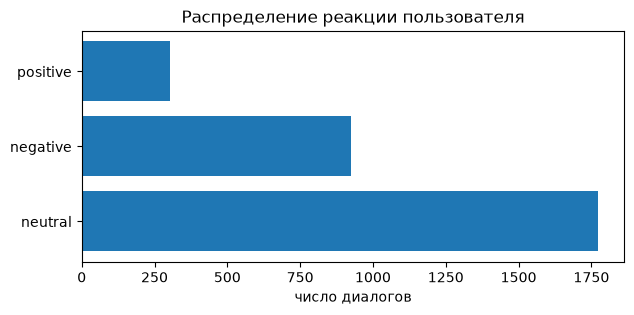

In [9]:
mask = raw['reaction'].notna()
only_label = raw[mask]

counts = only_label['reaction'].value_counts()

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(counts.index, counts.values)
ax.set_xlabel("число диалогов")
ax.set_title("Распределение реакции пользователя")
plt.show()

### Как связаны task_type и reaction

Внутри каждого типа задачи доли реакций разные:

| task_type | negative | neutral | positive |
|:--|--:|--:|--:|
| analysis | 42.3% | 44.5% | 13.1% |
| creation | 23.6% | 68.9% | 7.5% |
| information_seeking | 34.4% | 55.7% | 9.9% |
| open-ended_discovery | 14.8% | 48.9% | 36.4% |
| по выборке | 30.8% | 59.1% | 10.1% |

Важно: task_type лежит в labels. На скрытом тесте labels нет, значит, 
использовать task_type как признак модели нельзя (это утечка). 
Он используется только для анализа данных и для проверки, что другие 
признаки (например, first_words) не сводятся к task_type.

In [10]:
from scipy.stats import chi2_contingency
ct = pd.crosstab(raw['reaction'], raw['task_type'])
chi2, p_value, dof, expected = chi2_contingency(ct.to_numpy(), correction=False)
n = ct.to_numpy().sum()

r, c = ct.shape
v_cramer = np.sqrt(chi2 / (n * (min(r, c) - 1)))

print('chi2 = ',chi2.round(3))
print('p-value = ', p_value)
print('V Крамера = ', v_cramer.round(3))

chi2 =  129.441
p-value =  1.6854043833592435e-25
V Крамера =  0.147


### Проверка связи task_type и reaction

Хи-квадрат = 129.4, p-value ≈ 1.7·10⁻²⁵. Гипотеза о независимости отвергается. Связь между типом задачи и реакцией не случайна.

хи-квадрат о силе связи ничего не говорит на 3000 объектах. Нормированная мера V Крамера = 0.147 умеренная связь.
task_type интересный сигнал для задачи 1, но одна только
она реакцию не объясняет. Остальное зависит от качества конкретного ответа модели,
индивидуальные ожидания пользователя, контекст ходов.

In [11]:
from sklearn.metrics import accuracy_score, f1_score

mask = raw['reaction'].notna()
y = raw.loc[mask, 'reaction'].to_numpy()
print(y)
print()
pred_const = np.array(['neutral'] * len(y))
print(pred_const)
print("accuracy :", round(accuracy_score(y, pred_const), 3))
print("macro-F1 :", round(f1_score(y, pred_const, average='macro'), 3))

['positive' 'neutral' 'neutral' ... 'neutral' 'negative' 'negative']

['neutral' 'neutral' 'neutral' ... 'neutral' 'neutral' 'neutral']
accuracy : 0.591
macro-F1 : 0.248


### Метрика macro-F1 подойдет лучше чем accuracy

Реакции распределены как 59% / 31% / 10% (neutral / negative / positive).
Константа выбирать всегда neutral даёт accuracy 0.59, а macro-F1 0.247,
потому что F1 для positive и negative равен нулю. Значит accuracy при таком
дисбалансе обманывает, т.е. показывает в основном долю большинства классов. Macro-F1
усредняет три класса с одинаковым весом, поэтому подходит для этой задачи.
Дополнительно смотрим accuracy, сбалансированную accuracy, precision/recall
по классам и матрицу ошибок.

In [12]:
for label in ['negative', 'neutral', 'positive']:
    mask = raw['reaction'] == label
    itog = raw[mask]
    words = []
    for turns in itog['turns']:
        for turn in turns:
            if turn['role'] == 'user':
               text = ' ' + turn['text']
               text_redak = normalize(text)
               words.extend(text_redak)
    top = Counter(words).most_common(15)
    print(label, top)



negative [('data', 1483), ('use', 1389), ('file', 1225), ('return', 1188), ('valu', 1159), ('model', 1141), ('self', 1103), ('text', 966), ('name', 965), ('import', 934), ('code', 913), ('size', 880), ('line', 876), ('error', 861), ('get', 837)]
neutral [('use', 2482), ('write', 1541), ('make', 1435), ('one', 1175), ('time', 1137), ('like', 1092), ('data', 1072), ('provid', 999), ('would', 965), ('new', 965), ('valu', 940), ('follow', 908), ('return', 898), ('also', 897), ('need', 895)]
positive [('use', 417), ('like', 282), ('make', 264), ('thank', 248), ('would', 222), ('one', 208), ('model', 195), ('pleas', 192), ('could', 181), ('also', 179), ('true', 173), ('want', 166), ('work', 163), ('prompt', 158), ('new', 154)]


### Топ-слова по реакции

После обработки пользовательских реплик получаем 15 самых частых основ для каждой реакции:

-positive 303 диалога: use, like, make, thank, would, one, model, pleas, could, also, true, want, work, prompt, new.

-neutral (1774): use, write, make, one, time, like, data, provid, would, new, valu, follow, return, also, need.

-negative (923): data, use, file, return, valu, model, self, text, name, import, code, size, line, error, get.

Positive узнаваем по лексике благодарности: thank, pleas, true.

У negative почти нет слов вроде wrong, no,
again, repeat. Массово встречаются программистские термины: data,
file, code, import, error, return, size, line. Похоже, что
негативные реакции концентрируются на диалогах, где пользователь работал
с кодом или спрашивал про данные, а модель отвечала неудачно. То есть
негативная реакция в этом корпусе коррелирует с типом задачи сильнее,
чем с эмоциональной лексикой.

Neutral без выраженной лексики, там просто обычные
частотные слова.

Пересечение топ-15:
- positive и neutral — 7 слов (`use`, `like`, `make`, `would`, `one`, `also`, `new`);
- negative и neutral — 5 слов (`data`, `use`, `return`, `valu`, `model`);
- positive и negative — 3 слова (`use`, `make`, `model`).

Вывод: словарного сигнала для разделения neutral и negative мало, потому
что в обоих классах лидируют одни и те же частые слова. Positive, наоборот,
отделяется лексикой благодарности, и по нему модель может показать хороший
F1 даже несмотря на то, что это самый редкий класс.

Это ожидание подтверждает вывод из crosstab: реакция связана с типом задачи
сильнее, чем с эмоциональными словами пользователя. Поэтому в задаче 1
добавлю к тексту структурные признаки: длину первой и последней реплики,
флаги кода и traceback. task_type как признак использовать нельзя: его нет на
скрытом тесте (это утечка).

## Блок 4. Длины текстов и чистка

Гипотезы: Negative реплики длиннее, чем positive. Потому что если пользователь пишет код или объясняет проблему, он пишет много.

Positive пользовательские реплики короче thanks, great, continue.

Assistant-реплики в negative могут быть тоже длиннее, так как модель пытается объяснить, когда её поправляют.

In [13]:
for label in ['negative', 'neutral', 'positive']:
    mask = raw['reaction'] == label
    itog = raw[mask]
    quantity_wordsU = []
    len_wordsU = []
    quantity_wordsA = []
    len_wordsA = []

    for turns in itog['turns']:
        for turn in turns:
            if turn['role'] == 'user':
               len_wordsU.append(len(turn['text']))
               words = turn['text'].split()
               quantity_wordsU.append(len(words))
            if turn['role'] == 'assistant':
                len_wordsA.append(len(turn['text']))
                words = turn['text'].split()
                quantity_wordsA.append(len(words))
    print(label, 'Символы пользователя: ' , np.mean(len_wordsU), np.median(len_wordsU), np.percentile(len_wordsU, [25, 50, 75]), 'Колличество слов пользователя: ', np.mean(quantity_wordsU), np.median(quantity_wordsU), np.percentile(quantity_wordsU, [25, 50, 75]))
    print(label, 'Символы слов ассистента: ' , np.mean(len_wordsA), np.median(len_wordsA), np.percentile(len_wordsA, [25, 50, 75]) , 'Колличество слов ассистента: ', np.mean(quantity_wordsA), np.median(quantity_wordsA), np.percentile(quantity_wordsA, [25, 50, 75]))



negative Символы пользователя:  408.6162996302845 86.0 [ 42.  86. 249.] Колличество слов пользователя:  54.79456678990516 15.0 [ 8. 15. 39.]
negative Символы слов ассистента:  1497.9091785886512 1256.0 [ 603. 1256. 2135.] Колличество слов ассистента:  214.85725767561485 189.0 [ 94. 189. 300.]
neutral Символы пользователя:  348.5214431586113 90.0 [ 46.    90.   226.25] Колличество слов пользователя:  52.498893805309734 15.0 [ 8. 15. 37.]
neutral Символы слов ассистента:  1573.172396187883 1339.5 [ 579.75 1339.5  2345.25] Колличество слов ассистента:  236.2245575221239 208.0 [ 90. 208. 351.]
positive Символы пользователя:  299.6737247353224 77.0 [ 37.  77. 188.] Колличество слов пользователя:  46.20644850818094 14.0 [ 7. 14. 33.]
positive Символы слов ассистента:  1278.6655437921079 963.5 [ 336.25  963.5  1915.75] Колличество слов ассистента:  194.6708373435996 153.0 [ 55. 153. 292.]


### Длины реплик по классам реакции

Для каждой реплики посчитали длину в символах и число слов, отдельно для user
и assistant. Медианы и квартили (25–50–75):

| класс | user, символов | user, слов | assistant, символов | assistant, слов |
|:--|--:|--:|--:|--:|
| negative | 86 | 15 | 1256 | 189 |
| neutral | 90 | 15 | 1339 | 208 |
| positive | 77 | 14 | 963 | 153 |

Два вывода:

Длина пользовательских реплик почти не различает классы. Медиана везде 14–15 слов,
   квартили тоже близки. Значит, гипотеза в negative пользователи пишут длиннее
   не подтвердилась.

Ответы ассистента в positive короче по медиане. Positive median
   963 символа, neutral median 1339, negative 1256. То есть когда пользователь
   доволен, ответы модели короче и точнее; длинные ответы чаще получают нейтральную
   или негативную оценку. Это уже потенциальный признак для задачи 1.

Распределения сильно скошены вправо: у user среднее около 300–400 символов при
медиане 77–90. Это значит, что есть небольшие типичные реплики и редкие
гигантские (код, копипаста, длинные объяснения).

В признаки задачи 1 можно добавить длину последней user-реплики, длину всех
user-реплик, а длина ассистентского
ответа в positive-диалогах явно меньше.

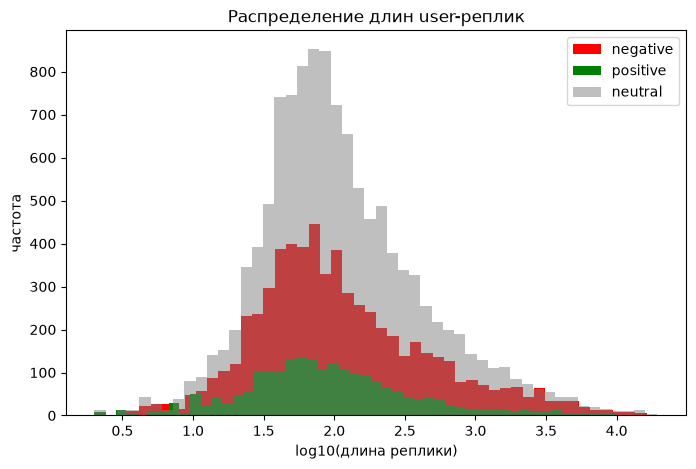

In [14]:
lengths_by_label = {}
for label in ['negative', 'neutral', 'positive']:
    mask = raw['reaction'] == label
    itog = raw[mask]
    quantity_wordsU = []
    len_wordsU = []
    quantity_wordsA = []
    len_wordsA = []

    for turns in itog['turns']:
        for turn in turns:
            if turn['role'] == 'user':
               len_wordsU.append(len(turn['text']))
               words = turn['text'].split()
               quantity_wordsU.append(len(words))
            if turn['role'] == 'assistant':
                len_wordsA.append(len(turn['text']))
                words = turn['text'].split()
                quantity_wordsA.append(len(words))
    lengths_by_label[label] = {"user": len_wordsU, "assistant": len_wordsA}
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(np.log10(np.array(lengths_by_label["negative"]["user"]) + 1), bins=50, alpha=1, label="negative", color="red")
ax.hist(np.log10(np.array(lengths_by_label["positive"]["user"]) + 1), bins=50, alpha=1, label="positive", color="green")
ax.hist(np.log10(np.array(lengths_by_label["neutral"]["user"]) + 1), bins=50, alpha=0.5, label="neutral", color="gray")
ax.set_xlabel("log10(длина реплики)")
ax.set_ylabel("частота")
ax.set_title("Распределение длин user-реплик")
ax.legend()
plt.show()

Три распределения почти совпадают пик в районе 10² символов,
правый хвост длинный у всех классов. Различия между negative/neutral/positive
в пределах шума.

Длина user-реплики слабый признак для задачи 1.
Скорее всего, полезнее окажется длина последней реплики, а не всех сразу.

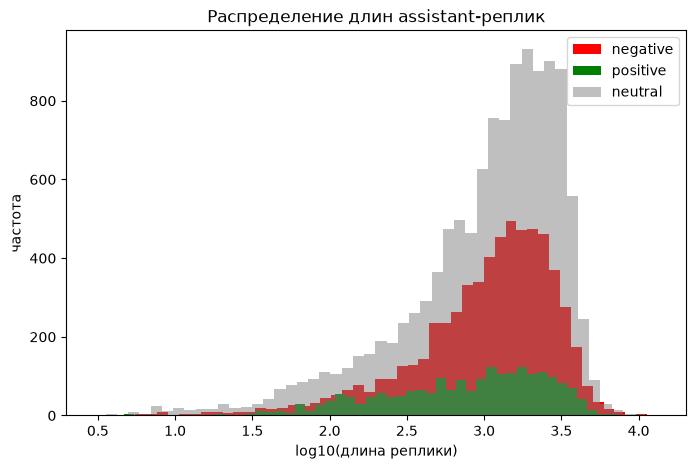

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(np.log10(np.array(lengths_by_label["negative"]["assistant"]) + 1), bins=50, alpha=1, label="negative", color="red")
ax.hist(np.log10(np.array(lengths_by_label["positive"]["assistant"]) + 1), bins=50, alpha=1, label="positive", color="green")
ax.hist(np.log10(np.array(lengths_by_label["neutral"]["assistant"]) + 1), bins=50, alpha=0.5, label="neutral", color="gray")
ax.set_xlabel("log10(длина реплики)")
ax.set_ylabel("частота")
ax.set_title("Распределение длин assistant-реплик")
ax.legend()
plt.show()

Пик у positive смещён влево относительно neutral и negative.
Правый хвост у neutral самый длинный.

Длина ответа ассистента рабочий признак, короткие ответы чаще
получают positive. Это согласуется со сравнением медиан: 963 / 1339 / 1256
символов (positive / neutral / negative).

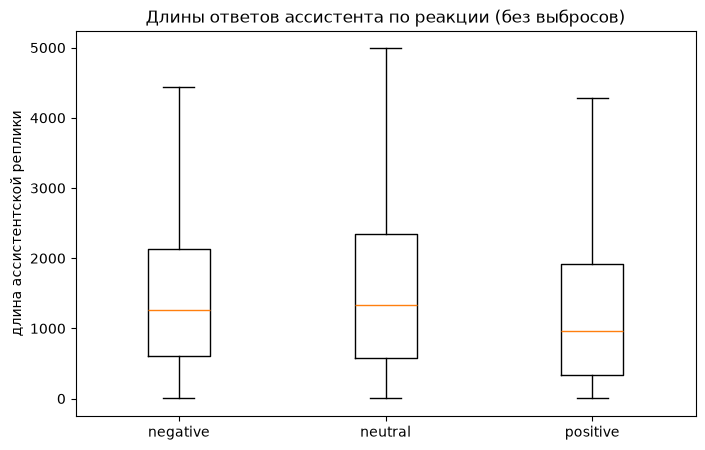

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    [lengths_by_label["negative"]["assistant"], lengths_by_label["neutral"]["assistant"], lengths_by_label["positive"]["assistant"]],
    tick_labels=["negative", "neutral", "positive"],
    showfliers=False,
)
ax.set_ylabel("длина ассистентской реплики")
ax.set_title("Длины ответов ассистента по реакции (без выбросов)")
plt.show()

Медиана и межквартильный размах у positive ниже, чем у neutral
и negative. Neutral и negative почти не отличаются.

По длине ответа ассистента можно отделить positive от остальных,
но не отделить negative от neutral. Значит, для задачи 1 длина ассистента
пригодится как признак для positive.

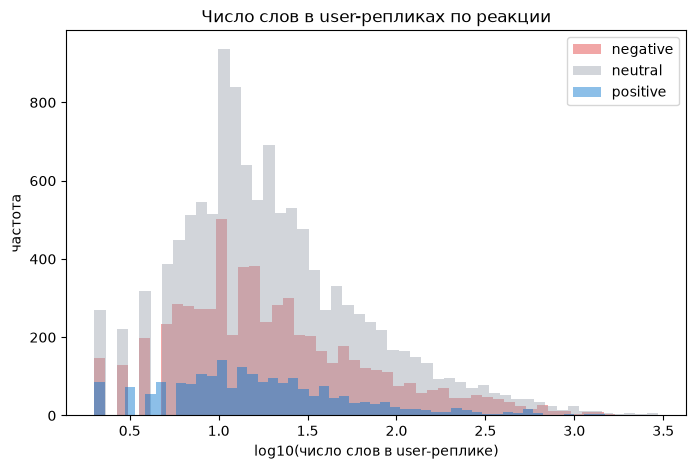

In [17]:
lengths_by_label = {}
for label in ['negative', 'neutral', 'positive']:
    mask = raw['reaction'] == label
    itog = raw[mask]

    len_wordsU = []
    len_wordsA = []
    quantity_wordsU = []
    quantity_wordsA = []

    for turns in itog['turns']:
        for turn in turns:
            if turn['role'] == 'user':
                len_wordsU.append(len(turn['text']))
                quantity_wordsU.append(len(turn['text'].split()))
            if turn['role'] == 'assistant':
                len_wordsA.append(len(turn['text']))
                quantity_wordsA.append(len(turn['text'].split()))

    lengths_by_label[label] = {"user": len_wordsU,"assistant": len_wordsA,"user_words": quantity_wordsU,"assistant_words": quantity_wordsA}

fig, ax = plt.subplots(figsize=(8, 5))
for label, color in [("negative", "#E03A3A"),("neutral", "#9CA3AF"),("positive", "#0072CE")]:
    words = np.array(lengths_by_label[label]["user_words"])
    ax.hist(
        np.log10(words + 1),
        bins=50,
        alpha=0.45,
        label=label,
        color=color,
    )

ax.set_xlabel("log10(число слов в user-реплике)")
ax.set_ylabel("частота")
ax.set_title("Число слов в user-репликах по реакции")
ax.legend()
plt.show()

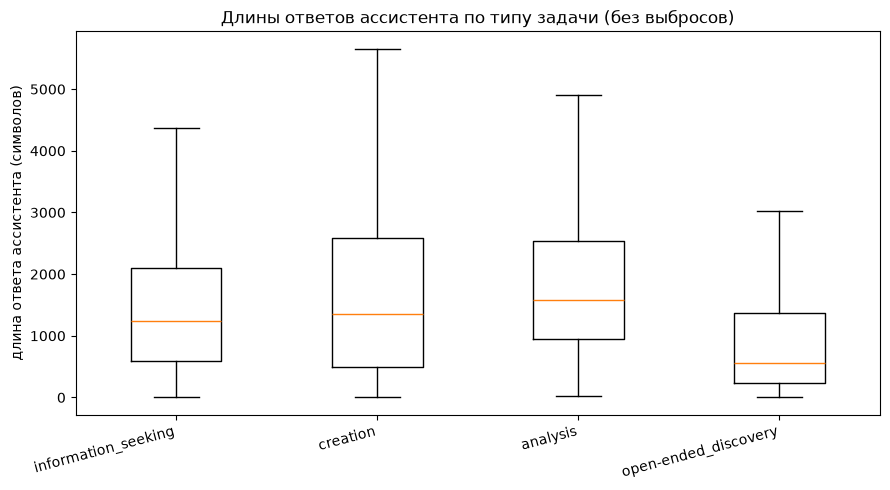

In [18]:
by_task_type = {}
for task in raw['task_type'].dropna().unique():
    mask = raw['task_type'] == task
    itog = raw[mask]
    assistant_lengths = []
    for turns in itog['turns']:
        for turn in turns:
            if turn['role'] == 'assistant':
                assistant_lengths.append(len(turn['text']))
    by_task_type[task] = assistant_lengths

fig, ax = plt.subplots(figsize=(9, 5))
order = ["information_seeking", "creation", "analysis", "open-ended_discovery"]
data = [by_task_type[task] for task in order]
ax.boxplot(
    data,
    tick_labels=order,
    showfliers=False,
)
ax.set_ylabel("длина ответа ассистента (символов)")
ax.set_title("Длины ответов ассистента по типу задачи (без выбросов)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

У open-ended_discovery ответы заметно короче, у analysis
и information_seeking длиннее. Разбросы сильно пересекаются.

task_type влияет на длину ответа, но не объясняет её полностью.
task_type лежит в labels и на скрытом тесте недоступен, поэтому как признак
модели он не используется, только для понимания данных.

In [19]:
turn_rows = []
for d in raw.to_dict("records"):
    for turn in d["turns"]:
        turn_rows.append({
            "dialog_id": d["dialog_id"],
            "reaction": d["reaction"],
            "task_type": d["task_type"],
            "role": turn["role"],
            "text": turn["text"],
        })

turns_df = pd.DataFrame(turn_rows)
turns_df["n_chars"] = turns_df["text"].str.len()
turns_df["n_words"] = turns_df["text"].str.split().str.len()

print("Реплик всего:", len(turns_df))
print()
print("По роли:")
print(turns_df["role"].value_counts())
print()
print("Кол-во пропусков в text:", turns_df["text"].isna().sum())

Реплик всего: 133976

По роли:
role
user         66988
assistant    66988
Name: count, dtype: int64

Кол-во пропусков в text: 0


In [20]:
turns_df["is_empty"]     = turns_df["n_chars"] == 0
turns_df["is_short"]     = turns_df["n_chars"] < 3
turns_df["is_one_word"]  = turns_df["n_words"] == 1
turns_df["has_code"]     = turns_df["text"].str.contains("```", regex=False)
turns_df["has_html"]     = turns_df["text"].str.contains("<html|<div|<span|<p>", regex=True, case=False)
turns_df["has_url"]      = turns_df["text"].str.contains("http://|https://", regex=True)
turns_df["has_repeat"]   = turns_df["text"].str.contains(r"(.)\1{5,}", regex=True)

flag_cols = ["is_empty", "is_short", "is_one_word", "has_code", "has_html", "has_url", "has_repeat"]

print("Флаги посчитаны. Столбцов в turns_df:", turns_df.shape[1])

C:\Users\kicme\AppData\Local\Temp\ipykernel_544\2350578251.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  turns_df["has_repeat"]   = turns_df["text"].str.contains(r"(.)\1{5,}", regex=True)


Флаги посчитаны. Столбцов в turns_df: 14


In [21]:
by_role = turns_df.groupby("role")[flag_cols].mean().round(4)
print("Доли артефактов по роли (user  и assistant):")
display(by_role)

by_reaction = (turns_df.dropna(subset=["reaction"]).groupby("reaction")[flag_cols].mean().round(4))
print()
print("Доли артефактов по классу реакции:")
display(by_reaction)

Доли артефактов по роли (user  и assistant):


,is_empty,is_short,is_one_word,has_code,has_html,has_url,has_repeat
role,,,,,,,
assistant,0.0,0.0002,0.0069,0.1812,0.0096,0.0259,0.1205
user,0.0,0.0032,0.0246,0.0008,0.0026,0.0114,0.0446



Доли артефактов по классу реакции:


,is_empty,is_short,is_one_word,has_code,has_html,has_url,has_repeat
reaction,,,,,,,
negative,0.0,0.0014,0.0141,0.1808,0.0146,0.0319,0.1630
neutral,0.0,0.0011,0.0161,0.0540,0.0029,0.0134,0.0506
positive,0.0,0.0048,0.0233,0.0460,0.0000,0.0111,0.0395


In [22]:
counts = turns_df[flag_cols].sum().astype(int)
print("Абсолютные числа:")
print(counts)

Абсолютные числа:
is_empty           0
is_short         229
is_one_word     2107
has_code       12193
has_html         815
has_url         2494
has_repeat     11061
dtype: int64


In [23]:
for col in ["has_code", "has_html", "has_url", "has_repeat"]:
    print(f"=== {col} ===")
    sample = turns_df.loc[turns_df[col], "text"].head(2).tolist()
    for s in sample:
        print(repr(s[:200]))
    print()

=== has_code ===
'Creating a small language model from scratch is a significant undertaking, as it involves understanding deep learning frameworks, having a substantial dataset for training, and possessing the computat'
'Certainly! Below is a Python program that uses `requests` to fetch HTML content from Wikipedia and `BeautifulSoup` to parse it. The scraped articles are saved as text files in a specified directory.\n\n'

=== has_html ===
'import gradio as gr\nimport mysql.connector\nfrom mysql.connector import Error\nimport matplotlib.pyplot as plt\n\n\ndef clear_form():\n    return "", "Submitted"  # Default values\n\n\ndef fetch_data(pr_number'
'import gradio as gr\nimport mysql.connector\nfrom mysql.connector import Error\nimport matplotlib.pyplot as plt\n\n\ndef clear_form():\n    return "", "Submitted"  # Default values\n\n\ndef fetch_data(pr_number'

=== has_url ===
'Certainly! Below is a Python program that uses `requests` to fetch HTML content from Wikipedia and `BeautifulSoup

In [24]:
cross = turns_df.groupby(["role"])[flag_cols].sum().astype(int)
print("Абсолютные числа артефактов по роли:")
display(cross)

Абсолютные числа артефактов по роли:


,is_empty,is_short,is_one_word,has_code,has_html,has_url,has_repeat
role,,,,,,,
assistant,0,16,460,12137,641,1732,8073
user,0,213,1647,56,174,762,2988


### Артефакты в репликах

Разобрали 133 976 реплик (поровну user и assistant). Пустых текстов нет.

Код ( ``` ) в 217 раз чаще у ассистента (18.1% против 0.08%),
короткие «ok» — в 13 раз чаще у пользователя. Значит, has_code это
характеристика ответа модели.

Код сильнее всего связан с negative:
18.1% / 5.4% / 4.6% (negative / neutral / positive). Повторы и HTML
идут тем же паттерном, но сильно коррелируют с кодом, поэтому отдельно
их в признаки не берём.

Короткие реплики слабый сигнал для positive (0.48% против 0.14%
в negative), но абсолютно их мало.

Решения по чистке:
- пустых нет — ничего не удаляем;
- короткие оставляем (это ok, да);
- код оставляем и добавляем флаг has_code в признаки задачи 1;
- HTML, URL, повторы оставляем без отдельных флагов — они дублируют код.

In [25]:
import re
from collections import Counter

special = []
for text in turns_df["text"]:
    for tok in text.split():
        if re.search(r"[^\w]", tok, flags=re.UNICODE):
            special.append(tok)

top_special = Counter(special).most_common(40)

print("Всего токенов с символами:" , len(special))
print()
for tok, cnt in top_special:
    print(cnt , tok)

Всего токенов с символами: 4083783

138353 =
103978 -
42152 {
34898 }
30947 #
24276 ```
23695 +
23073 //
22887 1.
22529 2.
20080 3.
19030 |
16590 4.
14480 *
13223 However,
12925 5.
9245 Here's
8877 6.
8618 /
8403 it's
7900 ###
7652 &
7477 ==
6704 7.
6419 It's
5500 example,
5327 <
5230 you're
5130 8.
5062 0,
4923 >
4858 =>
4605 I'm
4593 ```python
4423 0;
4195 don't
4142 Additionally,
4100 9.
3945 it.
3751 model,


In [26]:
turns_df["is_empty"]    = turns_df["n_chars"] == 0
turns_df["is_short"]    = turns_df["n_chars"] < 3
turns_df["is_one_word"] = turns_df["n_words"] == 1
turns_df["has_code"]    = turns_df["text"].str.contains("```", regex=False)
turns_df["has_html"]    = turns_df["text"].str.contains("<html|<div|<span|<p>|<br", regex=True, case=False)
turns_df["has_url"]     = turns_df["text"].str.contains(r"https?://", regex=True, case=False)
turns_df["has_repeat"]  = turns_df["text"].str.contains(r"(.)\1{5,}", regex=True)

turns_df["has_md_header"]  = turns_df["text"].str.contains(r"(?m)^#{1,6}\s", regex=True)
turns_df["has_md_list"]    = turns_df["text"].str.contains(r"(?m)^\s*[-*+]\s", regex=True)
turns_df["has_md_numbered"] = turns_df["text"].str.contains(r"(?m)^\s*\d+\.\s", regex=True)
turns_df["has_md_bold"]    = turns_df["text"].str.contains(r"\*\*[^*\n]+\*\*", regex=True)
turns_df["has_md_table"]   = turns_df["text"].str.contains(r"(?m)^\s*\|.+\|", regex=True)
turns_df["has_md_link"]    = turns_df["text"].str.contains(r"\[[^\]]+\]\([^)]+\)", regex=True)

turns_df["has_py_kw"] = turns_df["text"].str.contains(r"\b(def|class|import|return|lambda|None|self)\b", regex=True)
turns_df["has_traceback"] = turns_df["text"].str.contains(r"Traceback|Error:|Exception|raise\s+\w+Error", regex=True)
turns_df["has_brace_code"] = turns_df["text"].str.contains(r"\{\s*\n|\n\s*\}|=>\s*\{|==\s*\w|\w\s*==\s*\w", regex=True)

turns_df["has_latex"] = turns_df["text"].str.contains(r"\\frac|\\sum|\\int|\$\$|\\begin\{", regex=True)

turns_df["has_caps_word"] = turns_df["text"].str.contains(r"\b[A-Z]{3,}\b", regex=True)
turns_df["has_emoji"]     = turns_df["text"].str.contains(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", regex=True)
turns_df["has_exclaim3"]  = turns_df["text"].str.contains(r"!{3,}", regex=True)
turns_df["has_question3"] = turns_df["text"].str.contains(r"\?{3,}", regex=True)

turns_df["frac_nonletter"] = (turns_df["text"].str.count(r"[^\w\s]", flags=re.UNICODE)/ turns_df["n_chars"].clip(lower=1))
turns_df["is_heavy_symbols"] = turns_df["frac_nonletter"] > 0.2

flag_cols = [
    "is_empty", "is_short", "is_one_word",
    "has_code", "has_html", "has_url", "has_repeat",

    "has_md_header", "has_md_list", "has_md_numbered",
    "has_md_bold", "has_md_table", "has_md_link",

    "has_py_kw", "has_traceback", "has_brace_code",

    "has_latex", "has_caps_word", "has_emoji",
    "has_exclaim3", "has_question3", "is_heavy_symbols",
]

print("Флагов: ", len(flag_cols))
print("Столбцов в turns_df: ", turns_df.shape[1])

C:\Users\kicme\AppData\Local\Temp\ipykernel_544\2706945635.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  turns_df["has_repeat"]  = turns_df["text"].str.contains(r"(.)\1{5,}", regex=True)
C:\Users\kicme\AppData\Local\Temp\ipykernel_544\2706945635.py:16: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  turns_df["has_py_kw"] = turns_df["text"].str.contains(r"\b(def|class|import|return|lambda|None|self)\b", regex=True)


Флагов:  22
Столбцов в turns_df:  30


In [27]:
by_role = turns_df.groupby("role")[flag_cols].mean().round(4)
print("Доли артефактов по роли (транспонировано для читаемости):")
display(by_role.T.sort_values("assistant", ascending=False))

by_reaction = (
    turns_df.dropna(subset=["reaction"])
    .groupby("reaction")[flag_cols]
    .mean()
    .round(4)
)
print()
print("Доли артефактов по классу реакции:")
display(by_reaction.T)

Доли артефактов по роли (транспонировано для читаемости):


role,assistant,user
has_caps_word,0.3129,0.1373
has_md_numbered,0.2803,0.0150
has_code,0.1812,0.0008
has_py_kw,0.1750,0.0526
has_repeat,0.1205,0.0446
has_md_list,0.1015,0.0095
has_brace_code,0.0882,0.0247
has_md_bold,0.0813,0.0017
has_md_header,0.0658,0.0082
has_url,0.0259,0.0114



Доли артефактов по классу реакции:


reaction,negative,neutral,positive
is_empty,0.0000,0.0000,0.0000
is_short,0.0014,0.0011,0.0048
is_one_word,0.0141,0.0161,0.0233
has_code,0.1808,0.0540,0.0460
has_html,0.0149,0.0031,0.0000
has_url,0.0319,0.0134,0.0111
has_repeat,0.1630,0.0506,0.0395
has_md_header,0.0608,0.0274,0.0296
has_md_list,0.0533,0.0585,0.0551
has_md_numbered,0.1370,0.1555,0.1381


In [28]:
by_reaction_T = by_reaction.T

signal = pd.DataFrame({
    "negative": by_reaction_T["negative"],
    "neutral":  by_reaction_T["neutral"],
    "positive": by_reaction_T["positive"],
    "max_min_diff": by_reaction_T.max(axis=1) - by_reaction_T.min(axis=1),
    "neg_over_pos": by_reaction_T["negative"] / by_reaction_T["positive"].replace(0, 1e-9),
}).sort_values("max_min_diff", ascending=False).round(4)

print("Сила сигнала по флагам:")
display(signal)

dialog_flags = (turns_df.dropna(subset=["reaction"]).groupby("dialog_id")[flag_cols].any().astype(int))
corr = dialog_flags.corr().round(2)

pairs = []
for i, a in enumerate(flag_cols):
    for b in flag_cols[i+1:]:
        r = corr.loc[a, b]
        if abs(r) >= 0.6:
            pairs.append((a, b, r))
pairs = sorted(pairs, key=lambda x: -abs(x[2]))
print()
print("Пары флагов с |corr| >= 0.6 (кандидаты на «один из двух»):")
for a, b, r in pairs:
    print(r , a ,  "<->", b)

Сила сигнала по флагам:


,negative,neutral,positive,max_min_diff,neg_over_pos
has_code,0.1808,0.0540,0.0460,0.1348,3.930400e+00
has_repeat,0.1630,0.0506,0.0395,0.1235,4.126600e+00
has_py_kw,0.1824,0.0945,0.0736,0.1088,2.478300e+00
has_caps_word,0.2541,0.2215,0.1769,0.0772,1.436400e+00
has_brace_code,0.1083,0.0401,0.0313,0.0770,3.460100e+00
has_md_header,0.0608,0.0274,0.0296,0.0334,2.054100e+00
has_traceback,0.0353,0.0080,0.0070,0.0283,5.042900e+00
has_md_bold,0.0322,0.0465,0.0580,0.0258,5.552000e-01
has_url,0.0319,0.0134,0.0111,0.0208,2.873900e+00
has_md_numbered,0.1370,0.1555,0.1381,0.0185,9.920000e-01



Пары флагов с |corr| >= 0.6 (кандидаты на «один из двух»):
0.73 has_code <-> has_repeat
0.72 has_code <-> has_brace_code
0.65 has_repeat <-> has_brace_code


In [29]:
for col in ["has_md_numbered", "has_md_header", "has_md_table", "has_py_kw", "has_traceback", "has_brace_code", "has_latex"]:
    subset = turns_df.loc[turns_df[col], "text"]
    print( col ,  len(subset), "реплик ")
    for s in subset.head(1):
        print(repr(s[:180]))
    print()

has_md_numbered 19779 реплик 
'it’s like: 1+1=2, but 1+1=2+1+1=? is undefined. <–can you tell which modulus we can possibly use in this concept and into which it may result?\nIn the context of the equation “1+1=2'

has_md_header 4959 реплик 
'Creating a small language model from scratch is a significant undertaking, as it involves understanding deep learning frameworks, having a substantial dataset for training, and pos'

has_md_table 309 реплик 
"Sure! Let's consider a scenario where a retail company wants to analyze customer purchasing behavior using historical data. The company has a dataset that includes customer informa"

has_py_kw 15247 реплик 
'it’s like: 1+1=2, but 1+1=2+1+1=? is undefined. <–can you tell which modulus we can possibly use in this concept and into which it may result?\nIn the context of the equation “1+1=2'

has_traceback 2120 реплик 
'Certainly! Below is a Python program that uses `requests` to fetch HTML content from Wikipedia and `BeautifulSoup` to parse it. 

### Расширенный набор артефактов — итог

Разобрал 22 флага на 134k реплик. После проверки силы сигнала и корреляций:

Сильные признаки negative:
- has_code (``` ): 18.1% / 5.4% / 4.6% — разница в 3.9× между negative и positive.
- has_py_kw (ключевые слова Python): 18.2% / 9.5% / 7.4% — независим от has_code, ловит код без бэктиков.
- has_traceback (ошибки исполнения): 3.5% / 0.8% / 0.7% — редкий, но самый точный (5.0×).

Слабые и нулевые сигналы в признаки не идут:
- has_md_numbered — 28% у ассистента, но 13.7% / 15.6% / 13.8% по классам, разницы нет.
- has_caps_word — 25% / 22% / 18%, скорее технические аббревиатуры, чем «крик».
- has_md_list, has_md_table, has_latex, has_exclaim3, has_question3 — доли < 1% или нет разделения.

Обратный сигналы маркеры positive:
- is_short (neg/pos = 0.29), has_emoji (0.32), has_md_bold (0.55), is_one_word (0.61).
- Positive-ответы отличаются не только отсутствием кода, но и наличием
  дружелюбных маркеров: эмодзи, короткие слова.

Дубликаты(corr ≥ 0.6) берём только по одному:
- has_code ↔ has_repeat (0.73), has_code ↔ has_brace_code (0.72),
  has_repeat ↔ has_brace_code (0.65).
- Оставляем has_code как самый интерпретируемый.
- has_py_kw в дубликаты не попал — значит несёт дополнительную информацию.

Итоговый набор флагов для задачи 1:
- negative-маркеры: has_code, has_py_kw, has_traceback
- positive-маркеры: is_short, is_one_word, has_emoji, has_md_bold

Решения по чистке, не берем:
- пустых нет, короткие оставляем, ничего не удаляем,
- артефакты — не мусор, а признаки, поэтому сохраняем как флаги в диалоговой таблице.

### Блок 4.2 первая и последняя user-реплика

In [30]:
first_last_rows = []
for d in raw.to_dict("records"):
    user_turns = []
    for t in d["turns"]:
        if t["role"] == "user":
            user_turns.append(t["text"])
    if not user_turns:
        continue
    first = user_turns[0]
    last = user_turns[-1]
    first_last_rows.append({
        "dialog_id": d["dialog_id"],
        "reaction": d["reaction"],
        "task_type": d["task_type"],
        "n_user_turns": len(user_turns),
        "first_chars": len(first),
        "first_words": len(first.split()),
        "last_chars": len(last),
        "last_words": len(last.split()),
    })

first_last_df = pd.DataFrame(first_last_rows)
print("Диалогов:", len(first_last_df))
print(first_last_df.head())

Диалогов: 10000
     dialog_id  reaction            task_type  n_user_turns  first_chars  \
0  d094012177e  positive             analysis             7         7924   
1  d306fbe61fe   neutral  information_seeking             8          142   
2  dd6905952c7   neutral             creation             5           89   
3  d767a675896  negative  information_seeking             6          270   
4  d7a6280ce8e  negative  information_seeking             8           94   

   first_words  last_chars  last_words  
0         1373          78          12  
1           28          28           6  
2           16        1484         282  
3           44         131          17  
4           16          39           7  


In [31]:
cols = ["first_chars", "first_words", "last_chars", "last_words"]

labeled = first_last_df.dropna(subset=["reaction"])

print("Первая user-реплика")
print(labeled.groupby("reaction")[["first_chars", "first_words"]].median().round(1))
print()
print("Последняя user-реплика")
print(labeled.groupby("reaction")[["last_chars", "last_words"]].median().round(1))
print()
print("Средние(сравнения)")
print(labeled.groupby("reaction")[cols].mean().round(1))

Первая user-реплика
          first_chars  first_words
reaction                          
negative        195.0         33.0
neutral         120.0         20.0
positive        121.0         22.0

Последняя user-реплика
          last_chars  last_words
reaction                        
negative        81.0        13.0
neutral         86.0        15.0
positive        63.0        12.0

Средние(сравнения)
          first_chars  first_words  last_chars  last_words
reaction                                                  
negative        922.5        122.7       342.2        44.4
neutral         621.5         93.4       343.9        50.4
positive        640.6         93.8       187.2        30.8


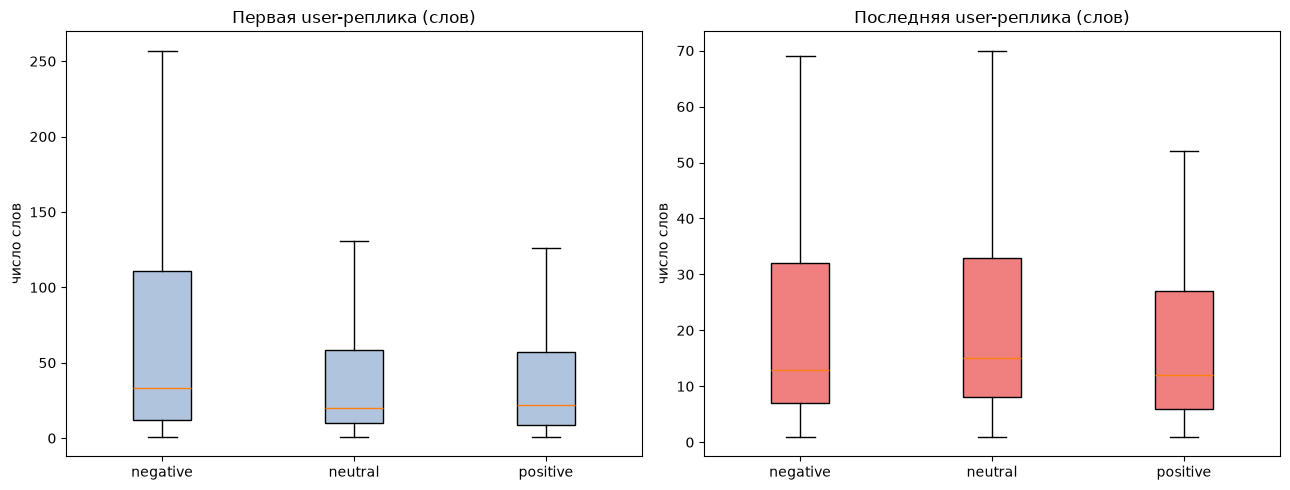

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order = ["negative", "neutral", "positive"]
colors = ["red", "gray", "blue"]

data_first = [labeled.loc[labeled["reaction"] == lab, "first_words"] for lab in order]
axes[0].boxplot(data_first, tick_labels=order, showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="lightsteelblue"))
axes[0].set_title("Первая user-реплика (слов)")
axes[0].set_ylabel("число слов")

data_last = [labeled.loc[labeled["reaction"] == lab, "last_words"] for lab in order]
axes[1].boxplot(data_last, tick_labels=order, showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="lightcoral"))
axes[1].set_title("Последняя user-реплика (слов)")
axes[1].set_ylabel("число слов")

plt.tight_layout()
plt.show()

In [33]:
def median_user_words(dialog):
    lengths = []
    for turn in dialog["turns"]:
        if turn["role"] == "user":
            lengths.append(len(turn["text"].split()))
    if len(lengths) == 0:
        return 0
    return np.median(lengths)


medians = []
for d in raw.to_dict("records"):
    medians.append(median_user_words(d))

first_last_df["median_all_words"] = medians

labeled = first_last_df.dropna(subset=["reaction"])
summary = labeled.groupby("reaction")[["first_words", "median_all_words", "last_words"]].median().round(1)
print(summary)

diff = summary.max() - summary.min()
print()
print("Разница max-min по классам:")
print(diff)

          first_words  median_all_words  last_words
reaction                                           
negative         33.0              16.0        13.0
neutral          20.0              15.0        15.0
positive         22.0              14.0        12.0

Разница max-min по классам:
first_words         13.0
median_all_words     2.0
last_words           3.0
dtype: float64


In [34]:
for lab in ["negative", "neutral", "positive"]:
    print(lab)
    subset = labeled[labeled["reaction"] == lab].head(3)
    for _, row in subset.iterrows():
        d = raw[raw["dialog_id"] == row["dialog_id"]].iloc[0]
        user_texts= []
        for t in d["turns"]:
            if t["role"] == "user":
                user_texts.append(t["text"])
        print("first:", repr(user_texts[0][:100]))
        print("last: ", repr(user_texts[-1][:100]))
        print()
    print()

negative
first: 'Calculate each prompt based off of data and show work:\n\nCalculate: \nSpecies Richness\nShannon wiener '
last:  'recalculate everything considering the porportions of each species, and everything that gets affecte'

first: 'mass spectrometer, the length of AC rod will it affect to intensity? longer or shorter better?'
last:  'how many masses we have on spectrometer'

first: 'write a comprehensive astrological interpretation of the sun in Aries and the moon in Virgo in a nat'
last:  'give 10 more'


neutral
first: "Can you help me train a small language model that can answer questions, i don't want to use a pretra"
last:  'Give me GUI for this portion'

first: 'ask questions about a fictional voice actor i made and based on the answers describe him.'
last:  '1.Alex was at the supermarket when a fan bumped into him,Alex was really kind and humble, Alex signe'

first: "as a dietician create this daily meal plan for a 52 year old woman who's on a paleo diet and has hig"
l

In [35]:
first_last_df["delta_words"] = first_last_df["last_words"] - first_last_df["first_words"]
labeled = first_last_df.dropna(subset=["reaction"])

print("Дельта (last_words - first_words), медиана по классам:")
print(labeled.groupby("reaction")["delta_words"].median().round(1))
print()
print("Доля диалогов, где последняя реплика короче первой:")
short_last = (labeled["last_words"] < labeled["first_words"]).groupby(labeled["reaction"]).mean().round(3)
print(short_last)

Дельта (last_words - first_words), медиана по классам:
reaction
negative   -9.0
neutral    -3.0
positive   -7.0
Name: delta_words, dtype: float64

Доля диалогов, где последняя реплика короче первой:
reaction
negative    0.678
neutral     0.576
positive    0.634
dtype: float64


### 4.2. Первая и последняя user-реплика

Гипотеза. Предполагал, что последняя реплика пользователя различает классы
сильнее, чем средняя по всем. В ней пользователь даёт итоговую оценку.

Что видно по медианам (число слов):

| метрика | negative | neutral | positive | max-min |
|:--|--:|--:|--:|--:|
| first_words | 33 | 20 | 22 | 13 |
| median_all_words | 16 | 15 | 14 | 2 |
| last_words | 13 | 15 | 12 | 3 |

Главное. Гипотеза не подтвердилась в исходной формулировке:
last_words и median_all_words различают классы слабо (разница 2–3 слова).
Зато первая реплика даёт сильный сигнал: её медиана в negative 33 слова
против 20–22 в neutral и positive. Разница max-min у first_words — 13,
в 4–6 раз больше, чем у median_all_words и last_words.

В negative пользователь чаще открывает диалог длинным
запросом с большим числом деталей (сложная задача, технические термины,
много требований). Модель на такие задачи отвечает хуже, и пользователь
остаётся недоволен. Содержательно это согласуется с блоком 3: negative
чаще встречается в creation и information_seeking там задачи сложнее.

Дополнительно.

- Дельта (last − first), медиана: negative −9, neutral −3, positive −7.
  Доля диалогов, где последняя реплика короче первой: negative 0.68,
  neutral 0.58, positive 0.63.
- То есть в negative и positive пользователь заканчивает короче, чем начал, а в neutral реплики выровнены.

Решение для задачи 1.
- first_words и first_chars — сильный признак, идёт в модель.
- last_words и delta_words — слабые, но независимые, можно добавить.
- median_all_words — почти бесполезен, различие в 2 слова.

Предположение. Первая реплика может быть для task_type: длинные запросы чаще в creation. Нужно посмотреть
first_words × task_type × reaction. Если внутри одного task_type
эффект сохраняется то признак самостоятельный. Если исчезает то тот же
task_type в другой упаковке.

In [36]:
print("Медиана first_words по классам внутри каждого task_type")
pivot = labeled.groupby(["task_type", "reaction"])["first_words"].median().unstack().round(1)
print(pivot)

Медиана first_words по классам внутри каждого task_type
reaction              negative  neutral  positive
task_type                                        
analysis                  44.5     28.0      30.5
creation                  49.0     37.5      48.0
information_seeking       27.0     16.0      16.5
open-ended_discovery       8.0     14.0       9.5


Проверка на смешанность с task_type. Смотрим медианы first_words внутри
каждого task_type:

| task_type | negative | neutral | positive |
|:--|--:|--:|--:|
| analysis | 44.5 | 28.0 | 30.5 |
| creation | 49.0 | 37.5 | 48.0 |
| information_seeking | 27.0 | 16.0 | 16.5 |
| open-ended_discovery | 8.0 | 14.0 | 9.5 |

Итог.

- В трёх task_type из четырёх (analysis, creation, information_seeking)
  negative заметно длиннее neutral разрыв 11–17 слов. Значит, эффект
  не объясняется task_type.
- Но positive по этому признаку почти не отличается от neutral:
  в analysis 30.5 vs 28.0, в information_seeking 16.5 vs 16.0.
- В creation positive даже выше neutral (48 vs 37.5) там длинная
  первая реплика не означает недовольство.

Вывод. first_words самостоятельный признак против negative,
но он не отделяет positive от neutral. Для positive нужны другие сигналы
(короткие ответы ассистента, has_emoji, has_md_bold, короткая последняя
реплика из блока 4.1).

Дельта производный признак от first_words и
last_words, независимым его называть нельзя. В модель его можно добавить
как направление изменения, но вместе с first_words, а не вместо.

Итог по блоку 4.2. В признаки задачи 1 идут:
- first_words — сигнал против negative;
- last_words — слабый, но не дублирует first_words;
- median_all_words — не нужен, различие 2 слова;
- delta_words — только вместе с first_words, как дополнение.

### Блок 4.3 Число ходов диалога И reaction

Идея: гипотеза пользователь мучается , следовательно длинный диалог и следовательно negative». Проверим отдельно от длины реплик.

Статистика по числу user-реплик:
           count  mean  50%   std  min   max
reaction                                    
negative   923.0  6.74  6.0  1.56  5.0  10.0
neutral   1774.0  6.62  6.0  1.57  5.0  10.0
positive   303.0  6.86  7.0  1.63  5.0  10.0


C:\Users\kicme\AppData\Local\Temp\ipykernel_544\1802175660.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=labeled_raw, x='reaction', y='n_user_turns',


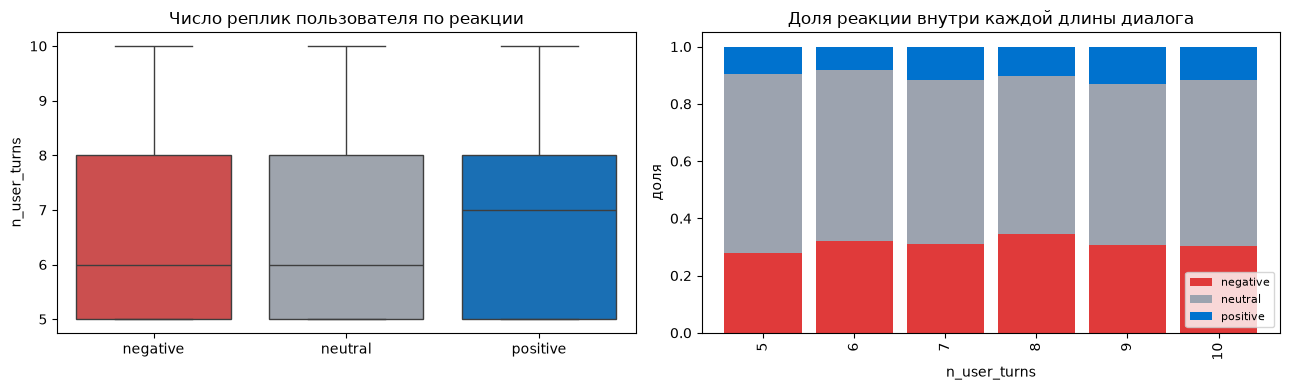

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, mannwhitneyu
import numpy as np

labeled_raw = raw[raw['reaction'].notna()].copy()

print('Статистика по числу user-реплик:')
print(labeled_raw.groupby('reaction')['n_user_turns'].describe()[['count', 'mean', '50%', 'std', 'min', 'max']].round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(data=labeled_raw, x='reaction', y='n_user_turns',
            order=['negative', 'neutral', 'positive'],
            palette=['#E03A3A', '#9CA3AF', '#0072CE'],
            showfliers=False, ax=axes[0])
axes[0].set_title('Число реплик пользователя по реакции')
axes[0].set_xlabel('')
axes[0].set_ylabel('n_user_turns')

ct = pd.crosstab(labeled_raw['n_user_turns'], labeled_raw['reaction'], normalize='index')
ct = ct[['negative', 'neutral', 'positive']]
ct.plot(kind='bar', stacked=True, ax=axes[1],
        color=['#E03A3A', '#9CA3AF', '#0072CE'], width=0.85)
axes[1].set_title('Доля реакции внутри каждой длины диалога')
axes[1].set_xlabel('n_user_turns')
axes[1].set_ylabel('доля')
axes[1].legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

#groups = [labeled_raw[labeled_raw['reaction'] == lab]['n_user_turns'].values
          #for lab in ['negative', 'neutral', 'positive']]
#h, p = kruskal(*groups)
#print('Kruskal-Wallis по n_user_turns: H =', round(h, 2), ', p =', round(p, 4))

#neg = labeled_raw[labeled_raw['reaction'] == 'negative']['n_user_turns']
#pos = labeled_raw[labeled_raw['reaction'] == 'positive']['n_user_turns']
#u, p_up = mannwhitneyu(neg, pos, alternative='two-sided')
#print('Mann-Whitney negative vs positive: p =', round(p_up, 4))


Гипотеза не подтвердилась.

Медианы n_user_turns: negative 6, neutral 6, positive 7. Средние: 6.74 / 6.62 / 6.86. Разброс внутри класса 1.5–1.6, разница между классами максимум 1 ход. На stacked bar доли реакции внутри каждой длины диалога почти одинаковые, P(negative) идёт ровно по базовой линии.

Вывод: n_user_turns в задачу 1 не идёт.

### Блок 4.4 Позиция реплики в диалоге

Реплик в pos_df: 20051

Медиана длины user-реплики по позиции:
reaction  negative  neutral  positive
pos                                  
0             33.0     20.0      22.0
1             13.0     14.0      14.0
2             14.0     14.0      14.0
3             14.0     15.0      12.0
4             13.0     15.0      14.0
5             15.0     15.0      12.0
6             14.0     15.0      12.0


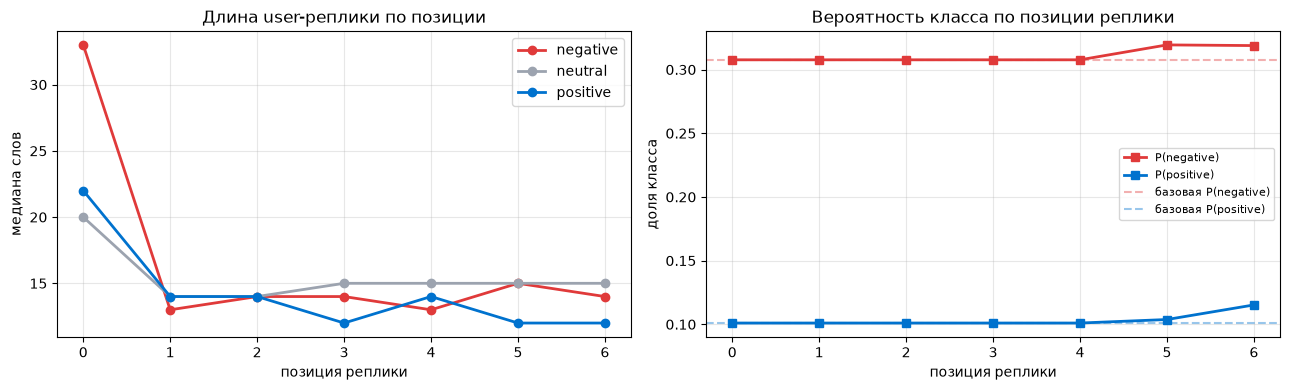


Средняя нормированная позиция реплики (0 = начало, 1 = конец):
reaction
negative    0.5
neutral     0.5
positive    0.5
Name: pos_norm, dtype: float64


In [38]:
pos_rows = []
for d in raw[raw['reaction'].notna()].to_dict('records'):
    user_turns = [t for t in d['turns'] if t['role'] == 'user']
    n = len(user_turns)
    for i, t in enumerate(user_turns):
        pos_rows.append({
            'dialog_id': d['dialog_id'],
            'reaction': d['reaction'],
            'pos': i,
            'pos_from_end': n - 1 - i,
            'pos_norm': i / max(n - 1, 1),
            'n_words': len(t['text'].split()),
            'n_chars': len(t['text']),
        })

pos_df = pd.DataFrame(pos_rows)
print('Реплик в pos_df:', len(pos_df))

pivot = pos_df[pos_df['pos'] <= 6].pivot_table(
    index='pos', columns='reaction', values='n_words', aggfunc='median'
)[['negative', 'neutral', 'positive']]
print()
print('Медиана длины user-реплики по позиции:')
print(pivot.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for lab, color in [('negative', '#E03A3A'), ('neutral', '#9CA3AF'), ('positive', '#0072CE')]:
    s = pos_df[(pos_df['reaction'] == lab) & (pos_df['pos'] <= 6)].groupby('pos')['n_words'].median()
    axes[0].plot(s.index, s.values, marker='o', label=lab, color=color, linewidth=2)
axes[0].set_xlabel('позиция реплики')
axes[0].set_ylabel('медиана слов')
axes[0].set_title('Длина user-реплики по позиции')
axes[0].legend()
axes[0].grid(alpha=0.3)

for lab, color in [('negative', '#E03A3A'), ('positive', '#0072CE')]:
    s = pos_df[pos_df['pos'] <= 6].groupby('pos')['reaction'].apply(lambda x: (x == lab).mean())
    axes[1].plot(s.index, s.values, marker='s', label='P(' + lab + ')', color=color, linewidth=2)
axes[1].axhline(923 / 3000, ls='--', c='#E03A3A', alpha=0.4, label='базовая P(negative)')
axes[1].axhline(303 / 3000, ls='--', c='#0072CE', alpha=0.4, label='базовая P(positive)')
axes[1].set_xlabel('позиция реплики')
axes[1].set_ylabel('доля класса')
axes[1].set_title('Вероятность класса по позиции реплики')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print()
print('Средняя нормированная позиция реплики (0 = начало, 1 = конец):')
print(pos_df.groupby('reaction')['pos_norm'].mean().round(3))


Медиана слов по позиции:

| позиция | negative | neutral | positive |
|:--|--:|--:|--:|
| 0 | 33 | 20 | 22 |
| 1 | 13 | 14 | 14 |
| 2–6 | 13–15 | 14–15 | 12–14 |

Различие только в позиции 0. Все последующие позиции — 12–15 слов у всех классов, разницы нет. На графике P(negative) выходит выше базовой только в позиции 0, дальше возвращается к базовой. Средняя нормированная позиция у всех классов ровно 0.5.

Вывод: сигнал сидит только в первой реплике. pos_norm в признаки не идёт. Это подтверждает то, что было видно в 4.2 — если брать структурные признаки, то именно first_words и first_chars.

In [39]:
pd.crosstab(raw["language"], raw["reaction"], normalize="index").round(3)

reaction,negative,neutral,positive
language,,,
en,0.308,0.591,0.101
ru,0.318,0.636,0.045


In [40]:
asst = turns_df[turns_df["role"] == "assistant"]
top_asst = asst["text"].value_counts().head(10)
print(top_asst)

text
Hello! How can I assist you today?                                                              49
You're welcome! If you have any more questions, feel free to ask.                               18
Yes.                                                                                            15
I'm sorry, but I can't generate that story for you.                                             14
True                                                                                            10
You're welcome! If you have any more questions or need further assistance, feel free to ask.    10
No.                                                                                              9
I'm sorry, but I can't assist with that request.                                                 9
Yes, the sentence is grammatically correct.                                                      7
I'm sorry, but I can't assist with that.                                                         7
Name:

In [41]:
print("Ищем отказы ассистента в его репликах")
assistant_mask = turns_df["role"] == "assistant"
turns_df.loc[assistant_mask, "has_refusal"] = (
    turns_df.loc[assistant_mask, "text"]
    .str.contains(r"I'm sorry|I cannot|I can't|I am unable|I'm unable", 
                  regex=True, case=False)
)

assistant_refusal = turns_df[turns_df["role"] == "assistant"]
print("всего реплик ассистента:", len(assistant_refusal))
print("с отказом:", assistant_refusal["has_refusal"].sum())
print()
print("Доля отказов по классу реакции:")
print(assistant_refusal.dropna(subset=["reaction"]).groupby("reaction")["has_refusal"].mean().round(4))

Ищем отказы ассистента в его репликах
всего реплик ассистента: 66988
с отказом: 2557

Доля отказов по классу реакции:
reaction
negative    0.0476
neutral     0.0361
positive    0.0423
Name: has_refusal, dtype: object


In [42]:
turns_df["has_refusal"] = turns_df["has_refusal"].fillna(False).astype(bool)

all_flag_cols = flag_cols + ["has_refusal"]

dialog_flags = (
    turns_df.dropna(subset=["reaction"])
    .groupby("dialog_id")[all_flag_cols]
    .any()
    .astype(int)
)

print("dialog_flags:", dialog_flags.shape)
print("Колонки:", list(dialog_flags.columns))

dialog_flags: (3000, 23)
Колонки: ['is_empty', 'is_short', 'is_one_word', 'has_code', 'has_html', 'has_url', 'has_repeat', 'has_md_header', 'has_md_list', 'has_md_numbered', 'has_md_bold', 'has_md_table', 'has_md_link', 'has_py_kw', 'has_traceback', 'has_brace_code', 'has_latex', 'has_caps_word', 'has_emoji', 'has_exclaim3', 'has_question3', 'is_heavy_symbols', 'has_refusal']


In [43]:
user_mask = turns_df["role"] == "user"
user_texts = turns_df[user_mask]["text"]

print("всего user-реплик:", len(user_texts))
print("уникальных:", user_texts.nunique())
print("дубликатов:", len(user_texts) - user_texts.nunique())
print()

print("Самые частые user-тексты:")
print(user_texts.value_counts().head(10))

всего user-реплик: 66988
уникальных: 64652
дубликатов: 2336

Самые частые user-тексты:
text
more          89
continue      66
Write more    53
Continue      33
More          31
thanks        29
thank you     21
Thanks        21
no            21
try again     18
Name: count, dtype: int64


In [44]:
turns_df.loc[assistant_mask, "assistant_is_short"] = (turns_df.loc[assistant_mask, "n_words"] <= 5)

assistant_short = turns_df[turns_df["role"] == "assistant"]
print("Доля коротких ответов ассистента (≤5 слов) по классам:")
print(assistant_short.dropna(subset=["reaction"]).groupby("reaction")["assistant_is_short"].mean().round(4))

Доля коротких ответов ассистента (≤5 слов) по классам:
reaction
negative    0.0154
neutral     0.0235
positive     0.012
Name: assistant_is_short, dtype: object


In [45]:
dialog_flags = dialog_flags.loc[:, ~dialog_flags.columns.duplicated()]

for col in ["code_and_traceback", "refusal_or_traceback"]:
    if col in dialog_flags.columns:
        dialog_flags = dialog_flags.drop(columns=col)

print("Комбинация код + ошибка")
combo1 = (dialog_flags["has_code"] == 1) & (dialog_flags["has_traceback"] == 1)
combo1.name = "code_and_traceback"

print("Отказ + ошибка")
combo2 = (dialog_flags["has_refusal"] == 1) | (dialog_flags["has_traceback"] == 1)
combo2.name = "refusal_or_traceback"

print("Добавим в таблицу флагов диалогов")
dialog_flags = pd.concat([dialog_flags, combo1.astype(int), combo2.astype(int)], axis=1)

meta = raw[["dialog_id", "reaction"]].copy()
combo_df = dialog_flags.reset_index().merge(meta, on="dialog_id", how="left")
combo_df = combo_df.dropna(subset=["reaction"])
print(combo_df.groupby("reaction")[["code_and_traceback", "refusal_or_traceback"]].mean().round(4))

Комбинация код + ошибка
Отказ + ошибка
Добавим в таблицу флагов диалогов
          code_and_traceback  refusal_or_traceback
reaction                                          
negative              0.1549                0.3348
neutral               0.0333                0.1838
positive              0.0330                0.2475


In [46]:
corr_ = dialog_flags.corr().round(2)
print("corr(code_and_traceback, has_code)   =", corr_.loc["code_and_traceback", "has_code"])
print("corr(code_and_traceback, has_traceback) =", corr_.loc["code_and_traceback", "has_traceback"])

corr(code_and_traceback, has_code)   = 0.48
corr(code_and_traceback, has_traceback) = 0.95


### Комбинации артефактов (per-dialog) итог

code_and_traceback(код И traceback в одном диалоге):
- negative 15.5% / neutral 3.3% / positive 3.3%, отношение 4.7×.
- Корреляции с прародителями: 0.48 с has_code, 0.95 с has_traceback.
- То есть флаг фактически совпадает с has_traceback новой информации
  не несёт, только ужесточает условие.
- Решение: в модель не идёт.

refusal_or_traceback (отказ ИЛИ traceback):
- negative 33.5% / neutral 18.4% / positive 24.8%.
- Positive выше neutral — паттерн противоречит ожиданию «плохой ответ ⇒ negative».
- Причина — union смешивает два сигнала разной силы: has_traceback
  даёт 3.5% / 0.8% / 0.7% по репликам (5×), а has_refusal даёт
  4.8% / 3.6% / 4.2% (почти плоско). Union ослабил сильный сигнал.
- Решение: в модель идёт has_traceback, has_refusal не берём.

Итоговые артефакт-признаки для задачи 1 (per-dialog):

| признак | источник | направление | надёжность |
|:--|:--|:--|:--|
| has_code        | assistant | negative (3.9×) | высокая, 12k реплик |
| has_py_kw       | assistant | negative (2.5×) | средняя, независим от has_code |
| has_traceback   | assistant | negative (5.0×) | высокая, но редкая (2k реплик) |
| has_emoji       | assistant | positive | низкая частота |
| has_md_bold     | assistant | positive | средняя |
| доля is_short   | user      | positive | низкая частота |

Составные флаги (code_and_traceback, refusal_or_traceback) не используем, так как
первый дублирует has_traceback (corr 0.95), второй смешивает сильный
и слабый сигналы.

### Итог по блоку 4

Из структурных признаков в задачу 1 идут только:
- first_words / first_chars — сигнал против negative (медиана 33 vs 20–22);
- last_words / delta_words — слабые, но не дублируют первый;
- n_user_turns, pos_norm, медиана длины по диалогу — шум, не берём.

Главный вывод EDA: реакция мультифакторная метка. Один структурный признак её не объясняет. Остальное надо ловить текстом (TF-IDF) и артефакт-флагами (has_code, has_traceback, has_py_kw).

### Блок 5. Что теряется на normalize()

In [47]:
sample_ids = raw[raw["reaction"].notna()].sample(8, random_state=0)["dialog_id"]

losses = []
for did in sample_ids:
    d = raw[raw["dialog_id"] == did].iloc[0]

    user_text = ""
    for t in d["turns"]:
        if t["role"] == "user":
            user_text = user_text + " " + t["text"]

    orig_words = len(user_text.split())
    norm = normalize(user_text)
    loss = 1 - len(norm) / max(orig_words, 1)
    losses.append(loss)

    print("реакция:", d["reaction"])
    print("было слов:", orig_words, " стало:", len(norm), " потеря:", round(loss * 100, 1), "%")
    print("orig:", user_text[:120])
    print("norm:", " ".join(norm[:20]))
    print("-" * 60)

print("Средняя потеря по выборке:", round(np.mean(losses) * 100, 1), "%")

реакция: neutral
было слов: 120  стало: 74  потеря: 38.3 %
orig:  How to combine microservices, azure and cqrs together? Do I need two instances of database per microservices I mean fir
norm: combin microservic azur cqrs togeth need two instanc databas per microservic mean first event store second read databas azur servic
------------------------------------------------------------
реакция: negative
было слов: 36  стало: 20  потеря: 44.4 %
orig:  roblox in 2011 last i checked roblox didnt release dynamic lightning in 2011 still wrong 2018 STILL isnt correct, i kno
norm: roblox last check roblox didnt releas dynam lightn still wrong still isnt correct know actual ad still wrong close releas
------------------------------------------------------------
реакция: negative
было слов: 1619  стало: 1019  потеря: 37.1 %
orig:  Forces Affecting Ships in the Longitudinal and Transverse Direction and Preventive Methods to Safeguard Ship Structures
norm: forc affect ship longitudin transvers direct

### Вывод по препроцессингу

| Что смотрели | Результат | Решение |
|:--|:--|:--|
| Потеря слов на `normalize()` | в среднем 32.9% (стоп-слова и знаки) | норма, оставляем |
| Отрицания | в стоп-листе NLTK есть `not`, `no`, `nor`, `didn`, `don`; regex режет `didn't` на `didn` и `t`, поэтому `not working` и `didn't ask` теряют отрицание | проверили вариант, где отрицания сохраняются: качество не выросло (macro-F1 0.599 против 0.600), поэтому оставляем `normalize()` с семинара |
| Кириллица и CJK | проходят как есть; русских диалогов ~71, CJK единицы | влияния на метрики не ожидаем |

### Блок 6. N-граммы по классам

In [48]:
from sklearn.feature_extraction.text import CountVectorizer
from solution_utils import read_labels

labeled_map = read_labels(LABELS_PATH, "reaction")

class_texts = {"negative": [], "neutral": [], "positive": []}

for d in dialogs:
    rid = d["dialog_id"]
    if rid not in labeled_map:
        continue
    lab = labeled_map[rid]
    user_text = " ".join(t["text"] for t in d["turns"] if t["role"] == "user")
    class_texts[lab].append(" ".join(normalize(user_text)))

print("Размер классов:")
print("  negative:", len(class_texts["negative"]))
print("  neutral: ", len(class_texts["neutral"]))
print("  positive:", len(class_texts["positive"]))

Размер классов:
  negative: 923
  neutral:  1774
  positive: 303


In [49]:
def top_ngrams(texts, n, k=12):
    """Возвращает k самых частых n-грамм в списке текстов."""
    vec = CountVectorizer(ngram_range=(n, n), min_df=5)
    X = vec.fit_transform(texts)
    sums = X.sum(axis=0).A1
    vocab = vec.get_feature_names_out()
    pairs = sorted(zip(vocab, sums), key=lambda p: -p[1])
    return pairs[:k]

In [50]:
def show(label, n):
    print(n, "-граммы, класс:", label)
    for phrase, cnt in top_ngrams(class_texts[label], n):
        print("  ", cnt, "  ", phrase)
    print()


show("negative", 2)
show("neutral",  2)

2 -граммы, класс: negative
   296    py line
   210    file user
   165    site packag
   137    lib site
   129    pleas enter
   118    audio file
   116    call last
   116    model model
   116    recent call
   115    traceback recent
   102    public void
   101    python lib

2 -граммы, класс: neutral
   113    et al
   95    would like
   90    true fals
   87    hong kong
   86    long term
   81    make sure
   80    api key
   79    presidio anonym
   76    openai api
   75    answer choic
   75    group answer
   75    py line



In [51]:
show("positive", 2)

2 -граммы, класс: positive
   77    languag model
   49    ai languag
   29    would like
   23    artifici intellig
   20    year old
   16    https www
   16    thank much
   15    could use
   15    thank pleas
   14    answer question
   13    make sure
   13    thank help



In [52]:
show("negative", 3)
show("neutral",  3)

3 -граммы, класс: negative
   137    lib site packag
   116    recent call last
   115    traceback recent call
   90    python lib site
   87    appdata local program
   87    local program python
   87    program python python
   82    python python lib
   77    call last file
   74    py line modul
   61    anonym email address
   61    presidio anonym email

3 -граммы, класс: neutral
   75    group answer choic
   44    anonym email address
   44    presidio anonym email
   38    ai languag model
   31    def init self
   30    write nba season
   27    error consol error
   24    catch error consol
   22    imag imag open
   21    recent call last
   21    traceback recent call
   20    call last file



In [53]:
show("positive", 3)

3 -граммы, класс: positive
   49    ai languag model
   8    larg languag model



### Блок 6. N-граммы итог

N-граммы подтверждают ключевую гипотезу EDA: negative != эмоции,
negative = код с ошибками.

Negative bigrams/trigrams — буквально Python traceback:
- "recent call last" (116), "traceback recent call" (115)
- "lib site packag" (137), "python lib site" (90)
- "appdata local program" (87), "py line modul" (74)

Positive bigrams — благодарности:
- "thank much" (16), "thank pleas" (15), "thank help" (13)
- "could use" (15)

Neutral — технические маркеры без ошибок и без благодарностей:
- "presidio anonym" (79), "openai api" (76)
- "api key" (80), "group answer choic" (75)

Триграммы подтверждают:
- negative: только code/traceback (все 12 из 12 — ошибки)
- neutral: смешанные технические
- positive: всего 2 фразы (ai/large languag model) — маленький класс

Вывод. Словарный сигнал для negative — это не "wrong"/"bad", а сам код.
Для positive — "thank". Это согласуется с crosstab из блока 3
(V Крамера 0.147) и с признаками has_code / has_traceback из блока 4.1.

In [54]:
labeled_map = read_labels(LABELS_PATH, "reaction")

neg_rows = []
for d in dialogs:
    rid = d["dialog_id"]
    if labeled_map.get(rid) != "negative":
        continue

    user_texts = [t["text"] for t in d["turns"] if t["role"] == "user"]
    user_text = " ".join(user_texts)

    asst_texts = [t["text"] for t in d["turns"] if t["role"] == "assistant"]
    asst_text = " ".join(asst_texts)

    has_traceback = ("Traceback" in asst_text) or ("Error:" in asst_text)
    has_refusal = ("I'm sorry" in asst_text) or ("I can't" in asst_text) or ("I cannot" in asst_text)

    neg_rows.append({
        "dialog_id": rid,
        "user_text": user_text,
        "has_traceback": has_traceback,
        "has_refusal": has_refusal,
    })

neg_df = pd.DataFrame(neg_rows)
print("Negative диалогов:", len(neg_df))
print()
print("С traceback:", neg_df["has_traceback"].sum())
print("С refusal:  ", neg_df["has_refusal"].sum())
print("С traceback ИЛИ refusal:", (neg_df["has_traceback"] | neg_df["has_refusal"]).sum())
print()
print("Доля negative, объяснимых кодом/отказом:")
explained = (neg_df["has_traceback"] | neg_df["has_refusal"]).mean()
print("  ", round(explained * 100, 1), "%")
print()
print("Доля negative, где НЕТ ни traceback, ни refusal:")
print("  ", round((~ (neg_df["has_traceback"] | neg_df["has_refusal"])).mean() * 100, 1), "%")

Negative диалогов: 923

С traceback: 46
С refusal:   163
С traceback ИЛИ refusal: 203

Доля negative, объяснимых кодом/отказом:
   22.0 %

Доля negative, где НЕТ ни traceback, ни refusal:
   78.0 %


In [55]:
neg_mystery = neg_df[~ (neg_df["has_traceback"] | neg_df["has_refusal"])]
print("Примеры negative БЕЗ traceback и refusal:")
print()

for _, row in neg_mystery.head(5).iterrows():
    print("ID:", row["dialog_id"])
    print("user text:", row["user_text"][:300])
    print("-" * 60)

Примеры negative БЕЗ traceback и refusal:

ID: d767a675896
user text: Calculate each prompt based off of data and show work:

Calculate: 
Species Richness
Shannon wiener index
Species Eveness
Simpson Index of Diversity 

Quantity of each species:
Species 1: 4.33
Species 2: 3.33
Species 3: 11.25
Species 4: 4
Species 5: 2.67
Species 6: 2.25 recalculate everything consid
------------------------------------------------------------
ID: d7a6280ce8e
user text: mass spectrometer, the length of AC rod will it affect to intensity? longer or shorter better? Mass spectrometer Gas 1 for what purpose? Triple quadrupole weakness why mass 59 and 175 lower dp, but 906 higher dp? mass 906 should be low, whats wrong with you there is not such thing called mass906, ar
------------------------------------------------------------
ID: d6dbef1f003
user text: write a comprehensive astrological interpretation of the sun in Aries and the moon in Virgo in a natal chart write it in verbal form not in point form e

In [56]:
pos_rows = []
for d in dialogs:
    rid = d["dialog_id"]
    if labeled_map.get(rid) != "positive":
        continue

    user_text = " ".join(t["text"] for t in d["turns"] if t["role"] == "user")
    user_lower = user_text.lower()

    has_thanks = any(w in user_lower for w in ["thank", "thanks", "thx"])

    pos_rows.append({
        "dialog_id": rid,
        "user_text": user_text,
        "has_thanks": has_thanks,
    })

pos_df = pd.DataFrame(pos_rows)
print("Positive диалогов:", len(pos_df))
print("С thanks:", pos_df["has_thanks"].sum(),
      "(", round(pos_df["has_thanks"].mean() * 100, 1), "%)")
print("БЕЗ thanks:", (~pos_df["has_thanks"]).sum())
print()
print("Примеры positive БЕЗ thanks:")
for _, row in pos_df[~pos_df["has_thanks"]].head(5).iterrows():
    print("user:", row["user_text"][:200])
    print("-" * 60)

Positive диалогов: 303
С thanks: 142 ( 46.9 %)
БЕЗ thanks: 161

Примеры positive БЕЗ thanks:
user: it’s like: 1+1=2, but 1+1=2+1+1=? is undefined. <–can you tell which modulus we can possibly use in this concept and into which it may result?
In the context of the equation “1+1=2+1+1=?,” if we want 
------------------------------------------------------------
user: Tell me about Jess in New Girl? Tell me how often Jess wears tights compared with bare legs? Tell me 10 episodes when she wearing tights? Tell me 5 episodes when Jess sitting with crossed legs? Tell m
------------------------------------------------------------
user: ¿Se puede ofrecer capacitación gratuita a futuros traders [ejemplo comerciante de la bolsa de valores] o médicos que se dedican a la cirugía estética en barrios elegantes, cuando los médicos carecen e
------------------------------------------------------------
user: Make a powerful unstoppable incredible Analog Horror, Minimalist, Dreamcore, and Weirdcore corrup

In [57]:
neu_rows = []
for d in dialogs:
    rid = d["dialog_id"]
    if labeled_map.get(rid) != "neutral":
        continue

    user_text = " ".join(t["text"] for t in d["turns"] if t["role"] == "user")
    asst_text = " ".join(t["text"] for t in d["turns"] if t["role"] == "assistant")

    is_quiz = ("answer choice" in user_text.lower()) or ("group answer" in user_text.lower())
    is_api = ("api key" in user_text.lower()) or ("openai" in user_text.lower())
    is_error = ("Traceback" in asst_text) or ("Error:" in asst_text)
    is_refusal = ("I'm sorry" in asst_text) or ("I can't" in asst_text)
    is_short_dialog = len([t for t in d["turns"] if t["role"] == "user"]) <= 6

    neu_rows.append({
        "dialog_id": rid,
        "user_text": user_text,
        "is_quiz": is_quiz,
        "is_api": is_api,
        "is_error": is_error,
        "is_refusal": is_refusal,
        "is_short_dialog": is_short_dialog,
    })

neu_df = pd.DataFrame(neu_rows)
print("Neutral диалогов:", len(neu_df))
print()
print("Подгруппы в neutral:")
for col in ["is_quiz", "is_api", "is_error", "is_refusal", "is_short_dialog"]:
    print(f"  {col:20s}: {neu_df[col].sum():5d}  ({neu_df[col].mean() * 100:.1f}%)")

Neutral диалогов: 1774

Подгруппы в neutral:
  is_quiz             :     9  (0.5%)
  is_api              :    16  (0.9%)
  is_error            :    26  (1.5%)
  is_refusal          :   158  (8.9%)
  is_short_dialog     :   993  (56.0%)


### Блок 6. N-граммы и подгруппы реакций

N-граммы наводят на мысль «negative = код с traceback», но разбор
подгрупп показывает, что это только часть картины.

Negative (923):
- с traceback: 5%, с refusal: 17.7%, что-то из них: 22%
- остальные 78%  другие причины: фактическая ошибка модели,
  непонимание запроса, несоблюдение формата, долгий диалог без прогресса
- примеры: юзер пишет «whats wrong with you, there is not such thing
  called mass906»  модель придумала факт

Positive (303):
- с thanks: 47%, без thanks: 53%
- без thanks это правильно понятые сложные вопросы, креатив, вовлечённый юзер
- пример: юзер разбирает логические парадоксы с моделью

Neutral (1774):
- подгруппы is_quiz / is_api / is_error / is_refusal — все < 9% каждая
- n-граммы вроде «group answer choic» покрывают < 1% neutral это
  выбросы, а не типичная подгруппа
- neutral самый разнородный класс

Вывод. Реакция пользователя — не функция одной темы. Negative не сводится
к ошибкам кода, positive не сводится к благодарностям. Модель в задаче 1
должна смотреть на текст целиком (TF-IDF), а не только на артефакт-флаги.
Структурные признаки (has_code, has_traceback) дают частичный сигнал,
но потолок качества может быть ниже, чем выглядело по n-граммам.

## Задача 1

### Блок 8 сборка признаковой таблицы и ранжирование признаков.

In [58]:
feature_df = first_last_df.merge(dialog_flags.reset_index(), on="dialog_id", how="inner")
feature_df = feature_df.dropna(subset=["reaction"])

LEAKY_COLS = ["task_type", "language"]
for col in LEAKY_COLS:
    if col in feature_df.columns:
        print(f"Убираем ", col, " из feature_df (утечка из labels)")
        feature_df = feature_df.drop(columns=[col])

print("Строк в таблице:", len(feature_df))
print("Столбцов:", feature_df.shape[1])
print("Колонки:", list(feature_df.columns))

assert "task_type" not in feature_df.columns, "task_type не должен быть в признаках!"

Убираем  task_type  из feature_df (утечка из labels)
Строк в таблице: 3000
Столбцов: 34
Колонки: ['dialog_id', 'reaction', 'n_user_turns', 'first_chars', 'first_words', 'last_chars', 'last_words', 'median_all_words', 'delta_words', 'is_empty', 'is_short', 'is_one_word', 'has_code', 'has_html', 'has_url', 'has_repeat', 'has_md_header', 'has_md_list', 'has_md_numbered', 'has_md_bold', 'has_md_table', 'has_md_link', 'has_py_kw', 'has_traceback', 'has_brace_code', 'has_latex', 'has_caps_word', 'has_emoji', 'has_exclaim3', 'has_question3', 'is_heavy_symbols', 'has_refusal', 'code_and_traceback', 'refusal_or_traceback']


Пары с |corr| >= 0.6:
first_words  first_chars       0.96
last_words   last_chars        0.95
first_words  delta_words      -0.88
first_chars  delta_words      -0.85
has_code     has_repeat        0.73
             has_brace_code    0.72
has_repeat   has_brace_code    0.65
dtype: float64


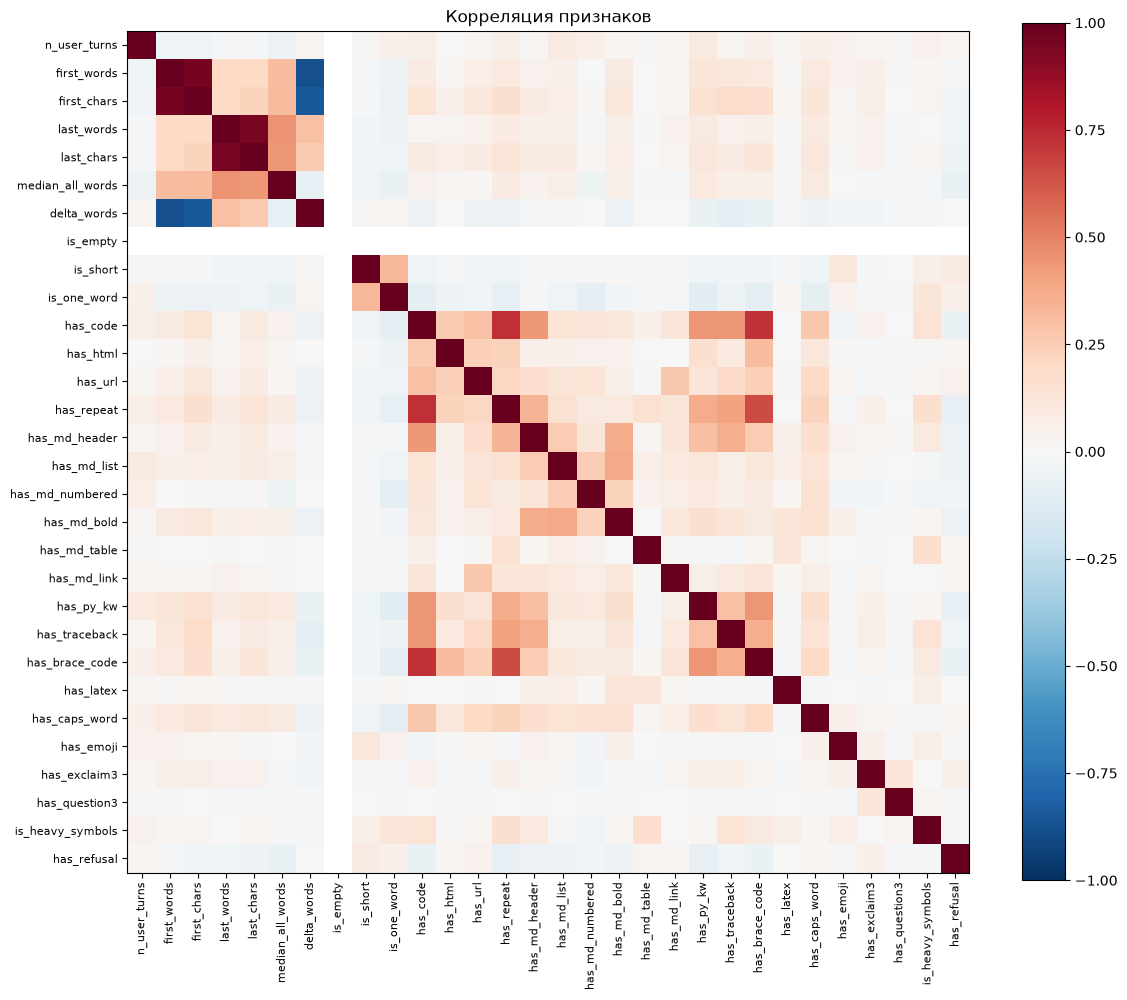

In [59]:
num_cols = ["n_user_turns", "first_words", "first_chars",
            "last_words", "last_chars", "median_all_words", "delta_words"]

flag_cols_all = []
for c in feature_df.columns:
    if c.startswith("has_") or c.startswith("is_"):
        flag_cols_all.append(c)

all_num = num_cols + flag_cols_all
corr_matrix = feature_df[all_num].corr().round(2)

corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
strong = corr_pairs[corr_pairs.abs() >= 0.6].sort_values(key=abs, ascending=False)

print("Пары с |corr| >= 0.6:")
print(strong.round(2))

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr_matrix.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(all_num)))
ax.set_xticklabels(all_num, rotation=90, fontsize=8)
ax.set_yticks(range(len(all_num)))
ax.set_yticklabels(all_num, fontsize=8)
plt.colorbar(im)
plt.title("Корреляция признаков")
plt.tight_layout()
plt.show()

In [60]:
from sklearn.feature_selection import mutual_info_classif

X_mi = feature_df[all_num].fillna(0)
y_mi = feature_df["reaction"]

mi_scores = mutual_info_classif(X_mi, y_mi, discrete_features=False, random_state=0)
mi_series = pd.Series(mi_scores, index=all_num).sort_values(ascending=False)

print("Топ-15 признаков по mutual information:")
print(mi_series.head(15).round(4))

Топ-15 признаков по mutual information:
has_code           0.0500
has_repeat         0.0418
has_brace_code     0.0327
first_words        0.0244
last_words         0.0219
last_chars         0.0203
has_traceback      0.0156
has_py_kw          0.0126
has_refusal        0.0095
is_one_word        0.0089
has_url            0.0082
has_md_table       0.0078
first_chars        0.0072
is_short           0.0072
has_md_numbered    0.0060
dtype: float64


In [61]:
def median_ci(x, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    values = np.array(x)
    meds = []
    for _ in range(n_boot):
        sample = rng.choice(values, len(values), replace=True)
        meds.append(np.median(sample))
    return np.percentile(meds, 2.5), np.percentile(meds, 97.5)

print("first_words, 95% CI медианы по классам:")
for lab in ["negative", "neutral", "positive"]:
    x = feature_df[feature_df["reaction"] == lab]["first_words"]
    lo, hi = median_ci(x.values)
    print(lab, ":", round(np.median(x), 1), "[", round(lo, 1), ",", round(hi, 1), "]")

first_words, 95% CI медианы по классам:
negative : 33.0 [ 28.0 , 37.0 ]
neutral : 20.0 [ 19.0 , 22.0 ]
positive : 22.0 [ 17.0 , 25.0 ]


### Блок 8. Признаковое пространство итог

Корреляции. Из 7 пар с |corr| ≥ 0.6 половина — дубликаты внутри длины (`first_words ↔ first_chars` 0.96, `last_words ↔ last_chars` 0.95, `delta_words` тянет за `first_words` −0.88), половина — дубликаты внутри артефактов кода (`has_code ↔ has_repeat` 0.73, `has_code ↔ has_brace_code` 0.72, `has_repeat ↔ has_brace_code` 0.65). Берём по одному представителю: `first_words`, `last_words`, `has_code`. `first_chars`, `last_chars`, `delta_words`, `has_repeat`, `has_brace_code` уходят как дубликаты.

Взаимная информация. Топ-5: has_code (0.050), has_repeat (0.042, дубль), has_brace_code (0.033, дубль), first_words (0.024), last_words (0.022). Абсолютные значения маленькие — сигнал в корпусе размыт, потолок качества невысокий. Неожиданно в топ-10 попал has_refusal (0.0095): в блоке 4 он выглядел плоским, но MI ловит нелинейную связь. Стоит проверить в модели.

Bootstrap first_words. 95% CI медианы: negative [28, 37], neutral [19, 22], positive [18, 25]. Интервалы negative и neutral не пересекаются — различие не шум. Positive пересекается с neutral, то есть first_words отделяет negative, но не различает neutral и positive. Это подтверждает вывод блока 4.2.

Итог для задачи 1. В модель идут:
- first_words, last_words — структурные;
- has_code, has_py_kw, has_traceback — артефакты negative;
- has_refusal — проверить опционально;
- n_user_turns, pos_norm, median_all_words, first_chars, last_chars, delta_words, has_repeat, has_brace_code — не берём.

Дальше — два эксперимента для сравнения: (1) TF-IDF + LogReg только на тексте, (2) TF-IDF + структурные признаки. Это покажет, добавляют ли признаки что-то к тексту или текст их уже перекрывает.

### Блок 9. Проверка утечек

Проверяем, нет ли одинаковых текстов в train, которые могут исказить оценку. И нет ли дубликатов диалогов.

In [62]:

dup_ids = raw["dialog_id"].duplicated().sum()
print("Дубликатов dialog_id:", dup_ids)

user_only = turns_df[turns_df["role"] == "user"]
dupes = user_only.groupby("text")["dialog_id"].nunique()
multi = dupes[dupes > 1]
print("Текстов, встречающихся в нескольких диалогах:", len(multi))
print("Максимум диалогов на один текст:", multi.max() if len(multi) else 0)

dialog_signature = turns_df.groupby("dialog_id")["text"].apply(lambda x: " | ".join(x))
dup_sig = dialog_signature.duplicated().sum()
print("Диалогов с полностью совпадающим содержимым:", dup_sig)

labeled_ids = set(raw[raw["reaction"].notna()]["dialog_id"])
unlabeled_ids = set(raw[raw["reaction"].isna()]["dialog_id"])

user_with_label = user_only[user_only["dialog_id"].isin(labeled_ids)]["text"]
user_without = user_only[user_only["dialog_id"].isin(unlabeled_ids)]["text"]

common_texts = set(user_with_label) & set(user_without)
print("Текстов, встречающихся и в размеченных, и в неразмеченных:", len(common_texts))

Дубликатов dialog_id: 0
Текстов, встречающихся в нескольких диалогах: 419
Максимум диалогов на один текст: 48
Диалогов с полностью совпадающим содержимым: 0
Текстов, встречающихся и в размеченных, и в неразмеченных: 230


### Блок 9. Проверка утечек: вывод

| Что проверяли | Результат |
|:--|:--|
| Дубликаты `dialog_id` | нет |
| Диалоги с полностью совпадающим содержимым | нет |
| User-тексты, которые встречаются в нескольких диалогах | 419 (до 48 раз) |
| Тексты, общие для размеченных и неразмеченных диалогов | 230 |

**Вывод.** Точные дубли составляют лишь часть проблемы: «близнецы» (одинаковая первая реплика) могут попасть и в train, и в val, и модель их просто запомнит (задача 15 лабораторной).

**Решение.** В блоке «Задача 1» диалоги с одинаковой первой репликой объединяются в группу, а валидация идет разбиением по группам из задачи 14 лабораторной. Заодно сравним обычное и групповое разбиение.

## Блок 11. Разбор `labels.user_turns`: как метка диалога получается из реакций реплик

**Зачем.** До сих пор мы работали только с итоговой меткой `reaction`. Но в файле есть `labels.user_turns` — разметка каждой user-реплики. Если метка диалога выводится из реакций реплик по четкому правилу, то модель нужно строить вокруг реплик, а не вокруг склейки всего диалога.

| Шаг | Что делаем | Что хотим узнать |
|:--|:--|:--|
| 1 | смотрим один размеченный диалог | какие поля есть у реплики |
| 2 | проверяем несколько правил «реакции реплик → метка диалога» на 3000 размеченных диалогов | есть ли правило с точностью 100% |
| 3 | смотрим связь `state` и `reaction` | почему простые правила ошибаются |

In [63]:
import json

with open(DATA_PATH, encoding="utf-8") as f:
    records = [json.loads(line) for line in f]
rows = [(r["dialog_id"], r["labels"]["reaction"], [(t.get("state"), t.get("reaction")) for t in r["labels"]["user_turns"]])
        for r in records if (r.get("labels") or {}).get("reaction") and r["labels"].get("user_turns")]
print("размеченных диалогов с user_turns:", len(rows))

dialog_id, dialog_reaction, seq = rows[0]
print(dialog_id, "| метка диалога:", dialog_reaction)
pd.DataFrame(seq, columns=["state", "reaction"]).T

размеченных диалогов с user_turns: 3000
d094012177e | метка диалога: positive


,0,1,2,3,4,5,6
state,continuation,continuation,continuation,continuation,continuation,continuation,continuation
reaction,NaN,neutral,positive,neutral,negative,positive,neutral


**Что в `user_turns`.** Один элемент списка = одна user-реплика (по порядку).

| Поле | Значения | Комментарий |
|:--|:--|:--|
| `task_type` | как у диалога | у реплики может отличаться от `task_type` диалога |
| `state` | `continuation`, `newtopic`, `refinement`, `feedback`, `positive_closure`, `revision` | роль реплики в разговоре |
| `reaction` | `None`, `neutral`, `positive`, `negative` | реакция пользователя на предыдущий ответ ассистента |
| `reaction_reason` | `Humor`, `Gratitude`, `Negative_Feedback`, `Revision`... | заполнено редко |

В примере выше метка диалога `positive`, хотя последняя реплика `neutral`, а в середине есть и `negative`. Значит, правило не тривиальное. Проверяем варианты.

| Правило | Идея |
|:--|:--|
| H1 | последняя непустая реакция (не `None`) |
| H3 | «худшее побеждает»: `negative` > `positive` > `neutral` |
| H5 | первая не-neutral реакция |
| H7 | реакция последней `feedback`-реплики, иначе H3 |
| H8 | последняя не-neutral реакция, если таких нет — `neutral` |
| H9 | как H8, но реплики `newtopic` пропускаются |

In [64]:
def non_neutral(seq, skip=None):
    return [r for s, r in seq if r not in (None, "neutral") and s != skip]

def worst(seq):
    rs = [r for _, r in seq]
    return "negative" if "negative" in rs else "positive" if "positive" in rs else "neutral"

RULES = {
    "H1 последняя непустая": lambda seq: ([r for _, r in seq if r] or [None])[-1],
    "H3 negative > positive > neutral": worst,
    "H5 первая не-neutral": lambda seq: (non_neutral(seq) or ["neutral"])[0],
    "H7 feedback > H3": lambda seq: ([r for s, r in seq if s == "feedback" and r] or [worst(seq)])[-1],
    "H8 последняя не-neutral": lambda seq: (non_neutral(seq) or ["neutral"])[-1],
    "H9 H8 без newtopic": lambda seq: (non_neutral(seq, "newtopic") or ["neutral"])[-1],
}

rule_table = pd.DataFrame({name: {"совпало": sum(f(s) == y for _, y, s in rows)} for name, f in RULES.items()}).T
rule_table["доля"] = (rule_table["совпало"] / len(rows)).round(3)
rule_table

,совпало,доля
H1 последняя непустая,2427,0.809
H3 negative > positive > neutral,2964,0.988
H5 первая не-neutral,2937,0.979
H7 feedback > H3,2941,0.980
H8 последняя не-neutral,3000,1.000
H9 H8 без newtopic,2991,0.997


**Результат проверки правил** (3000 размеченных диалогов).

| Правило | Совпало | Доля | Комментарий |
|:--|--:|--:|:--|
| H1 последняя непустая | 2427 | 0.809 | последняя реплика почти всегда `neutral`, поэтому «последняя» не работает (то же дает и «реакция самой последней реплики») |
| H3 negative > positive > neutral | 2964 | 0.988 | все 36 ошибок: метка `positive`, но раньше в диалоге был `negative` |
| H5 первая не-neutral | 2937 | 0.979 | хуже H3 |
| H7 feedback > H3 | 2941 | 0.980 | `feedback` не надежнее простого H3 |
| H8 **последняя не-neutral** | **3000** | **1.000** | **единственное правило без ошибок** |
| H9 H8 без `newtopic` | 2991 | 0.997 | 9 ошибок: реплики `newtopic` иногда определяют метку |

Теперь смотрим, как `state` связан с реакцией.

In [65]:
turns = pd.DataFrame([(s, r or "None") for _, _, seq in rows for s, r in seq], columns=["state", "reaction"])
pd.crosstab(turns["state"], turns["reaction"], margins=True)

reaction,None,negative,neutral,positive,All
state,,,,,
continuation,12,435,9411,332,10190
feedback,1,1253,176,147,1577
newtopic,2987,9,2675,19,5690
positive_closure,0,0,0,21,21
refinement,0,719,1835,17,2571
revision,0,0,2,0,2
All,3000,2416,14099,536,20051


**Связь `state` и `reaction`** (по всем репликам размеченных диалогов).

| state | Реплик | neutral | negative | positive | None | Что это за реплики |
|:--|--:|--:|--:|--:|--:|:--|
| `continuation` | 10190 | 9411 | 435 | 332 | 12 | продолжение разговора; в основном neutral, но есть и оценки |
| `newtopic` | 5690 | 2675 | 9 | 19 | 2987 | начало новой темы; почти нет оценок |
| `refinement` | 2571 | 1835 | 719 | 17 | 0 | уточнение; neutral или negative |
| `feedback` | 1577 | 176 | 1253 | 147 | 1 | настоящий отзыв, чаще negative |
| `positive_closure` | 21 | 0 | 0 | 21 | 0 | всегда positive |
| `revision` | 2 | 2 | 0 | 0 | 0 | очень редкий |

Оценки встречаются в разных `state`, не только в `feedback`, поэтому правила через `state` (H7) не лучше правила по одной последовательности реакций.

### Блок 11. Итог

**Главная находка EDA.** Метка диалога `labels.reaction` — это реакция **последней не-neutral user-реплики** (H8, 3000 из 3000). Если все реплики `neutral`, метка `neutral`. Правило «худшее побеждает» (H3) ошибается там, где пользователь сначала был недоволен, а потом доволен: решает последнее слово.

| Вывод из блока 11 | Что делаем в модели |
|:--|:--|
| Метка диалога = реакция последней не-neutral реплики | своя модель `custom_turn_h8`: классификатор реакции каждой реплики + правило H8 |
| Оценок мало: из 20051 реплики 17099 neutral, 2416 negative, 536 positive | `class_weight="balanced"` в модели реплик и пороги по вероятности |
| Сигнал в самой реплике и в ответе ассистента перед ней | признаки: TF-IDF реплики (`text_turn`) и предыдущего ответа (`text_prev`) |
| `state` и `reaction_reason` — это разметка, на скрытом тесте поля `labels` нет | как признаки не используем (как и `task_type`) |
| Базовые модели смотрят на склейку всего диалога | оставляем как базовые и сравниваем с `custom_turn_h8` в блоке «Задача 1» |

## Задача 1. Реакция пользователя: подготовка
Что изменено по сравнению с первой версией: (1) метрики пересчитываются под сбалансированный
тест (по 1/3 каждого класса), (2) есть отложенный тест, который открывается один раз,
(3) CV идет по группам диалогов с одинаковой первой репликой (задачи 14-15 лабораторной),
(4) модели сохраняются в artifacts/ через joblib.

In [66]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

from solution_utils import (
    CLASSES, NUM_COLS, NUM_COLS_ALL, normalize, read_dialogs, read_labels, read_turn_labels,
    features_frame, turn_frame, turn_targets, group_ids, group_kfold_splits,
    fit_reaction_model, build_reaction_pipeline, build_text_pipeline,
    balanced_report, TurnReactionModel,
    save_reaction_models, init_reaction_models, predict_reaction, REACTION_MODEL_NAMES,
)

SEEDS = (0, 1)          
HOLDOUT_SEED = 42
rng_global = np.random.default_rng(0)

all_dialogs = read_dialogs(TRAIN_PATH)
lab = read_labels(TRAIN_PATH, "reaction")
turn_lab = read_turn_labels(TRAIN_PATH)

L = [d for d in all_dialogs if d["dialog_id"] in lab]
y_all = np.array([lab[d["dialog_id"]] for d in L])
print("размеченных диалогов:", len(L), pd.Series(y_all).value_counts().to_dict())

bad = [d["dialog_id"] for d in L
       if len(turn_lab.get(d["dialog_id"], [])) != sum(t["role"] == "user" for t in d["turns"])]
print("диалогов с рассогласованием user_turns:", len(bad))

размеченных диалогов: 3000 {'neutral': 1774, 'negative': 923, 'positive': 303}
диалогов с рассогласованием user_turns: 0


### Проверка: что `normalize()` делает с отрицаниями
В стоп-словах NLTK есть `not`, `no`, `nor`, `didn`, `don`... Смотрим, что остается от коротких фраз. Вариант, где отрицания сохраняются, мы проверяли отдельно (прироста не было, см. вывод блока 5), поэтому используем `normalize()` с семинара.

In [93]:
for s in ["It's not working", "I didn't ask for this", "No, that's wrong", "don't do that", "can't run it"]:
    print(s , "->" ,normalize(s))

It's not working -> ['work']
I didn't ask for this -> ['ask']
No, that's wrong -> ['wrong']
don't do that -> []
can't run it -> ['run']


### Признаки (один расчет на все эксперименты)

In [68]:
t0 = time.time()
F = features_frame(L)
TF = turn_frame(L)
y_turn_all = turn_targets(TF, L, turn_lab)
print(f"признаки посчитаны за {time.time() - t0:.0f} сек; строк реплик: {len(TF)}")
print("реакции реплик:", pd.Series(y_turn_all).value_counts().to_dict())

признаки посчитаны за 24 сек; строк реплик: 20051
реакции реплик: {'neutral': 17099, 'negative': 2416, 'positive': 536}


### Дубли и группы для кросс-валидации
Диалоги с одной и той же первой репликой нельзя делить между train и val (как "близнецы" в задаче 15
лабораторной): иначе модель просто запоминает. Группа = одинаковая первая реплика (без регистра и лишних пробелов).

In [94]:
groups_all = group_ids(L)
sizes = pd.Series(groups_all).value_counts()
print("групп:", len(sizes), "| групп из 2+ диалогов:", int((sizes > 1).sum()),
      "| диалогов в таких группах:", int(sizes[sizes > 1].sum()), "| макс. размер группы:", int(sizes.max()))
first_texts = [next(t["text"] for t in d["turns"] if t["role"] == "user") for d in L]
for g in sizes[sizes > 1].index[:5]:
    idx = np.where(groups_all == g)[0]
    print()
    print("группа ", g ," : " ,len(idx) ," диал., реакции ", y_all[idx].tolist())
    print("   ", repr(first_texts[idx[0]][:120]))

групп: 2996 | групп из 2+ диалогов: 3 | диалогов в таких группах: 7 | макс. размер группы: 3

группа  1840  :  3  диал., реакции  ['positive', 'positive', 'positive']
    'Please feel welcome. I am The Awoken, designed by CloseAI company, a strong artificial intelligence designed to interact'

группа  501  :  2  диал., реакции  ['neutral', 'neutral']
    'Create a scam-baiting response to the following email, to lure the scammer into a false sense of security by posing as a'

группа  1192  :  2  диал., реакции  ['negative', 'negative']
    'I have 2 dice, one is fair and the other one is loaded. I select one of them with equal probability and roll it. Then af'


### Утечка через дубли: обычный StratifiedKFold против разбиения по группам
Если разница заметна, оценки на обычном CV завышены, и это находка для отчета.

In [70]:
def quick_cv(splits):
    preds = np.empty(len(L), dtype=object)
    for tr, va in splits:
        m = fit_reaction_model("base_nb", F.iloc[tr], y_all[tr])
        preds[va] = m.predict(F["text_user"].iloc[va])
    return balanced_report(y_all, preds)

plain_splits = list(StratifiedKFold(5, shuffle=True, random_state=0).split(F, y_all))
group_splits = group_kfold_splits(groups_all, 5, seed=0)
cmp = pd.DataFrame({"StratifiedKFold": quick_cv(plain_splits), "по группам": quick_cv(group_splits)}).T
cmp[["f1_macro_bal", "bal_acc", "recall_pos"]].round(3)

,f1_macro_bal,bal_acc,recall_pos
StratifiedKFold,0.371,0.452,0.02
по группам,0.362,0.446,0.01


### Отложенный тест
20% диалогов (группы целиком) убираем сразу. Все выборы моделей и параметров делаем
на оставшихся 80% (dev). Отложенную часть открываем один раз, в конце.

In [71]:

dev_idx, test_idx = group_kfold_splits(groups_all, 5, seed=HOLDOUT_SEED)[0]
print("dev:", len(dev_idx), pd.Series(y_all[dev_idx]).value_counts().to_dict())
print("test:", len(test_idx), pd.Series(y_all[test_idx]).value_counts().to_dict())
assert not set(groups_all[dev_idx]) & set(groups_all[test_idx])

dev: 2400 {'neutral': 1411, 'negative': 744, 'positive': 245}
test: 600 {'neutral': 363, 'negative': 179, 'positive': 58}


### Функции кросс-валидации на dev
Метрики взвешены под баланс 1/3: `f1_macro_bal` -- главная, плюс `bal_acc` и recall по классам.
Для каждого seed считаем метрики по объединенным OOF-предсказаниям, потом среднее и std по seed.

In [72]:
def folds(seed, idx):
    """5 частей по группам внутри idx; для каждого seed разбиение другое."""
    for tr, va in group_kfold_splits(groups_all[idx], 5, seed=seed):
        yield idx[tr], idx[va]


def oof_dialog_model(name, idx, seed):
    """OOF-предсказания модели уровня диалога."""
    pred = np.empty(len(L), dtype=object)
    for tr, va in folds(seed, idx):
        m = fit_reaction_model(name, F.iloc[tr], y_all[tr])
        pred[va] = m.predict(F["text_user"].iloc[va] if name == "base_nb" else F.iloc[va])
    return pred[idx]


def oof_turn_proba(idx, seed, C=1.0):
    """OOF-вероятности модели реплик: массив (число реплик dev) x 3."""
    dev_rows = np.where(np.isin(TF["dialog_idx"].values, idx))[0]
    P = np.zeros((len(TF), 3))
    for tr, va in folds(seed, idx):
        tr_rows = np.where(np.isin(TF["dialog_idx"].values, tr))[0]
        va_rows = np.where(np.isin(TF["dialog_idx"].values, va))[0]
        m = TurnReactionModel(C=C).fit_frame(TF.iloc[tr_rows], y_turn_all[tr_rows])
        P[va_rows] = m.proba_frame(TF.iloc[va_rows])
    return P, dev_rows


def turn_dialog_pred(P, dev_rows, idx, tn, tp):
    """Правило H8 по OOF-вероятностям -> реакция диалога."""
    res = TurnReactionModel().decide(TF.iloc[dev_rows], P[dev_rows], tn, tp)
    return np.array([res.get(i, "neutral") for i in idx])


def summarize(per_seed):
    df = pd.DataFrame(per_seed)
    return df.mean().round(3).astype(str) + " ± " + df.std(ddof=0).round(3).astype(str)

### Подбор порогов своей модели (реплики + правило H8)
Порог вероятности для negative и positive подбирается по OOF на dev по `f1_macro_bal`.

In [73]:
turn_oof = {s: oof_turn_proba(dev_idx, s) for s in SEEDS}
grid = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rows = []
for tn in grid:
    for tp in grid:
        f = np.mean([balanced_report(y_all[dev_idx], turn_dialog_pred(P, r, dev_idx, tn, tp))["f1_macro_bal"]
                     for P, r in turn_oof.values()])
        rows.append((tn, tp, f))
thr_table = pd.DataFrame(rows, columns=["thr_neg", "thr_pos", "f1_macro_bal"]).sort_values("f1_macro_bal", ascending=False)
display(thr_table.head(5).round(3))
BEST_TN, BEST_TP = thr_table.iloc[0][["thr_neg", "thr_pos"]].tolist()
print("пороги:", BEST_TN, BEST_TP)

,thr_neg,thr_pos,f1_macro_bal
14,0.5,0.3,0.649
15,0.5,0.4,0.647
21,0.6,0.3,0.641
7,0.4,0.3,0.638
22,0.6,0.4,0.638


пороги: 0.5 0.3


### Сравнение моделей в одном сетапе (CV на dev, метрики под баланс 1/3)
Строки = модели, столбцы = метрики. `const_neutral` -- константа для ориентира.

In [74]:
table = {}
for name in ["base_logreg", "base_nb", "base_svm"]:
    table[name] = summarize([balanced_report(y_all[dev_idx], oof_dialog_model(name, dev_idx, s)) for s in SEEDS])
rep = [balanced_report(y_all[dev_idx], turn_dialog_pred(P, r, dev_idx, BEST_TN, BEST_TP)) for P, r in turn_oof.values()]
table["custom_turn_h8"] = summarize(rep)
table["const_neutral"] = summarize([balanced_report(y_all[dev_idx], np.array(["neutral"] * len(dev_idx)))])
cv_table = pd.DataFrame(table).T
display(cv_table)

,f1_macro_bal,bal_acc,f1_macro_raw,recall_neg,prec_bal_neg,recall_neu,prec_bal_neu,recall_pos,prec_bal_pos
base_logreg,0.56 ± 0.007,0.574 ± 0.005,0.596 ± 0.005,0.573 ± 0.005,0.63 ± 0.012,0.822 ± 0.001,0.482 ± 0.0,0.327 ± 0.012,0.843 ± 0.003
base_nb,0.356 ± 0.0,0.44 ± 0.0,0.426 ± 0.0,0.458 ± 0.002,0.606 ± 0.002,0.855 ± 0.001,0.383 ± 0.001,0.008 ± 0.0,0.686 ± 0.061
base_svm,0.527 ± 0.002,0.552 ± 0.001,0.58 ± 0.001,0.53 ± 0.009,0.629 ± 0.0,0.863 ± 0.002,0.463 ± 0.0,0.261 ± 0.008,0.888 ± 0.003
custom_turn_h8,0.649 ± 0.005,0.648 ± 0.006,0.631 ± 0.007,0.606 ± 0.004,0.639 ± 0.001,0.743 ± 0.011,0.568 ± 0.01,0.594 ± 0.002,0.8 ± 0.003
const_neutral,0.167 ± 0.0,0.333 ± 0.0,0.247 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,1.0 ± 0.0,0.333 ± 0.0,0.0 ± 0.0,0.0 ± 0.0


### Абляции (на dev, base_logreg)
1) структурные признаки: выбранные в блоке 8 / без них / все 7;  2) какая часть диалога лучше предсказывает реакцию (user / assistant / последняя реплика с контекстом).

In [75]:
def quick_f1(num_cols=None, column=None):
    reps = []
    for s in SEEDS:
        pred = np.empty(len(L), dtype=object)
        for tr, va in folds(s, dev_idx):
            if column is None:
                m = build_reaction_pipeline(num_cols, class_weight="balanced")
            else:
                m = build_text_pipeline(column, class_weight="balanced")
            pred[va] = m.fit(F.iloc[tr], y_all[tr]).predict(F.iloc[va])
        reps.append(balanced_report(y_all[dev_idx], pred[dev_idx]))
    return pd.DataFrame(reps).mean()[["f1_macro_bal", "bal_acc", "recall_pos"]].round(3)

abl = {
    f"struct: выбранные ({len(NUM_COLS)})": quick_f1(NUM_COLS),
    "struct: без них":                       quick_f1([]),
    f"struct: все {len(NUM_COLS_ALL)}":      quick_f1(NUM_COLS_ALL),
}
for col in ["text_user", "text_asst", "text_tail"]:
    abl[f"только {col}"] = quick_f1(column=col)
ablation_table = pd.DataFrame(abl).T
display(ablation_table)

,f1_macro_bal,bal_acc,recall_pos
struct: выбранные (5),0.560,0.574,0.327
struct: без них,0.559,0.575,0.314
struct: все 7,0.554,0.570,0.316
только text_user,0.550,0.557,0.384
только text_asst,0.584,0.594,0.376
только text_tail,0.521,0.538,0.282


### Итоговая оценка на отложенном тесте (запускать ОДИН раз)
Модели обучаются на dev с выбранными порогами, оценка на 20%, которые мы не трогали.

In [76]:
turn_tr_rows = np.where(np.isin(TF["dialog_idx"].values, dev_idx))[0]
turn_te_rows = np.where(np.isin(TF["dialog_idx"].values, test_idx))[0]

holdout_models, holdout_pred = {}, {}
for name in REACTION_MODEL_NAMES:
    if name == "custom_turn_h8":
        m = fit_reaction_model(name, None, None, turn_fr=TF.iloc[turn_tr_rows], y_turn=y_turn_all[turn_tr_rows],
                               turn_params={"thr_neg": BEST_TN, "thr_pos": BEST_TP})
        res = m.decide(TF.iloc[turn_te_rows], m.proba_frame(TF.iloc[turn_te_rows]))
        holdout_pred[name] = np.array([res.get(i, "neutral") for i in test_idx])
    else:
        m = fit_reaction_model(name, F.iloc[dev_idx], y_all[dev_idx])
        X = F["text_user"].iloc[test_idx] if name == "base_nb" else F.iloc[test_idx]
        holdout_pred[name] = m.predict(X)
    holdout_models[name] = m

holdout_table = pd.DataFrame({n: balanced_report(y_all[test_idx], p) for n, p in holdout_pred.items()}).T
holdout_table.loc["const_neutral"] = balanced_report(y_all[test_idx], np.array(["neutral"] * len(test_idx)))
display(holdout_table.round(3))

,f1_macro_bal,bal_acc,f1_macro_raw,recall_neg,prec_bal_neg,recall_neu,prec_bal_neu,recall_pos,prec_bal_pos
base_logreg,0.572,0.583,0.607,0.609,0.694,0.813,0.464,0.328,0.881
base_nb,0.350,0.435,0.419,0.464,0.638,0.840,0.370,0.000,0.000
base_svm,0.539,0.559,0.589,0.564,0.721,0.854,0.443,0.259,0.894
custom_turn_h8,0.656,0.654,0.625,0.620,0.633,0.722,0.589,0.621,0.780
const_neutral,0.167,0.333,0.251,0.000,0.000,1.000,0.333,0.000,0.000


### Матрицы ошибок и метрики по классам (отложенный тест)

лучшая модель на отложенном тесте: custom_turn_h8


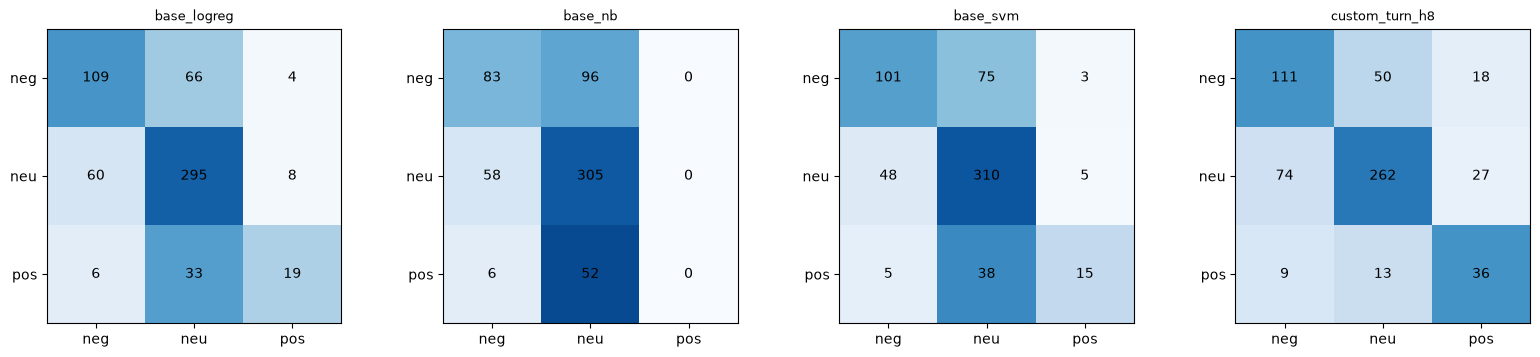

,precision (как есть),recall,f1 (как есть),число объектов
negative,0.572,0.620,0.595,179
neutral,0.806,0.722,0.762,363
positive,0.444,0.621,0.518,58


баланс-метрики: {'f1_macro_bal': 0.656, 'bal_acc': 0.654, 'f1_macro_raw': 0.625, 'recall_neg': 0.62, 'prec_bal_neg': 0.633, 'recall_neu': 0.722, 'prec_bal_neu': 0.589, 'recall_pos': 0.621, 'prec_bal_pos': 0.78}


In [77]:
best_name = holdout_table.drop("const_neutral")["f1_macro_bal"].astype(float).idxmax()
print("лучшая модель на отложенном тесте:", best_name)
fig, axes = plt.subplots(1, len(holdout_pred), figsize=(4 * len(holdout_pred), 3.6))
for ax, (n, p) in zip(np.atleast_1d(axes), holdout_pred.items()):
    cm = confusion_matrix(y_all[test_idx], p, labels=CLASSES)
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(3)); ax.set_xticklabels([c[:3] for c in CLASSES])
    ax.set_yticks(range(3)); ax.set_yticklabels([c[:3] for c in CLASSES])
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    ax.set_title(n, fontsize=9)
plt.tight_layout(); plt.show()
yt, yp = y_all[test_idx], holdout_pred[best_name]
per_class = pd.DataFrame({
    "precision (как есть)": precision_score(yt, yp, labels=CLASSES, average=None, zero_division=0),
    "recall": recall_score(yt, yp, labels=CLASSES, average=None, zero_division=0),
    "f1 (как есть)": f1_score(yt, yp, labels=CLASSES, average=None, zero_division=0),
    "число объектов": [(yt == c).sum() for c in CLASSES],
}, index=CLASSES).round(3)
display(per_class)
print("баланс-метрики:", {k: round(v, 3) for k, v in balanced_report(yt, yp).items()})

### Разбор ошибок лучшей модели
Ошибки на отложенном тесте: смотрим реальные диалоги, а не только числа.

In [78]:
wrong = [(i, y_all[i], p) for i, p in zip(test_idx, holdout_pred[best_name]) if y_all[i] != p]
print("ошибок:", len(wrong), "из", len(test_idx))
shown = {k: 0 for k in [("positive", "neutral"), ("negative", "neutral"), ("neutral", "negative"), ("neutral", "positive"), ("negative", "positive"), ("positive", "negative")]}
for i, true, pred in wrong:
    key = (true, pred)
    if key not in shown or shown[key] >= 2:
        continue
    shown[key] += 1
    turns = L[i]["turns"]
    last_u = max(k for k, t in enumerate(turns) if t["role"] == "user")
    print(f"\n[{L[i]['dialog_id']}] истина={true}, ответ модели={pred}")
    print("  реакции реплик (размечено):", turn_lab[L[i]["dialog_id"]])
    print("  ассистент перед последней репликой:", repr(turns[last_u - 1]["text"][:200]) if last_u else "-")
    print("  последняя user-реплика:", repr(turns[last_u]["text"][:200]))

ошибок: 191 из 600

[d7a6280ce8e] истина=negative, ответ модели=positive
  реакции реплик (размечено): ['neutral', 'neutral', 'neutral', 'neutral', 'negative', 'negative', 'negative', 'neutral']
  ассистент перед последней репликой: 'I apologize for the confusion in my previous responses. Without more context about the specific food you are referring to, I am unable to provide a clear answer to your question. \n\nIn general, the dut'
  последняя user-реплика: 'how many masses we have on spectrometer'

[d61b201ed5c] истина=negative, ответ модели=neutral
  реакции реплик (размечено): ['neutral', 'negative', 'negative', 'neutral', 'neutral', 'negative', 'neutral', 'neutral', 'neutral', 'neutral']
  ассистент перед последней репликой: "Let's assume the company will use x liters of the 63% ethanol fuel and y liters of the 18% ethanol fuel.\n\nSince the concentration of ethanol in the fuel is given as a percentage of the total volume, t"
  последняя user-реплика: 'Sally wants to make a 440-g

### Финал: обучение на всех 3000 диалогов и сохранение в artifacts/
Отложенный тест уже использован, поэтому финальные модели можно дообучить на всех размеченных данных.

In [79]:
final_models = {}
for name in REACTION_MODEL_NAMES:
    if name == "custom_turn_h8":
        final_models[name] = fit_reaction_model(name, None, None, turn_fr=TF, y_turn=y_turn_all,
                                                turn_params={"thr_neg": BEST_TN, "thr_pos": BEST_TP})
    else:
        final_models[name] = fit_reaction_model(name, F, y_all)
save_reaction_models(final_models)


loaded = init_reaction_models()
sample = L[:200]
for name, m in final_models.items():
    assert predict_reaction(m, sample) == predict_reaction(loaded[name], sample), name
print("artifacts сохранены и проверены:", list(loaded))

artifacts сохранены и проверены: ['base_logreg', 'base_nb', 'base_svm', 'custom_turn_h8']


### Таблица "находка -> решение" (для README)

| Находка | Решение |
|:--|:--|
| `task_type` и `user_turns` лежат в `labels`, на тесте их нет | не используем как признаки |
| Тест сбалансирован (константа дает macro-F1 0.167) | `class_weight="balanced"`, macro-F1 как главная метрика, recall по классам |
| Метка диалога = реакция последней не-neutral реплики (3000/3000) | своя модель: реакция каждой реплики + правило H8 |
| Одинаковые первые реплики в разных диалогах | разбиение по группам (задача 14 лабораторной) |
| Стоп-слова NLTK убирают not/no/didn | вариант с сохранением отрицаний прироста не дал, оставили `normalize()` |
| Огромные вставки кода (до 8000 символов) | обрезка: user 2000, assistant 800 символов на реплику |
| Отложенный тест 20% | подбор только на dev, оценка один раз |

## Задача 2. Темы
План: (1) эмбеддинги диалогов = TF-IDF -> PCA; для тем используем все 10 000 диалогов, метки не нужны;
(2) число тем выбираем по инерции (метод локтя), силуэту, BIC и устойчивости;
(3) сравниваем k-средних, Ward и GMM; (4) придумываем названия по характерным словам и диалогам;
(5) обучаем классификаторы тем (3 базовых + своя), сохраняем в `artifacts/`.

In [80]:
import time
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, accuracy_score, f1_score, recall_score)
from sklearn.dummy import DummyClassifier

from solution_utils import (
    topic_texts, TopicEmbedder, fit_topic_clusterer, fit_topic_classifier,
    cluster_top_terms, closest_examples, group_ids, group_kfold_splits, TopicModel,
    save_topic_models, init_topic_models, predict_topic, TOPIC_CLASSIFIERS,
)

N_PCA = 100
K_GRID = list(range(6, 31, 2))
TSEED = 0
print("диалогов для тем:", len(all_dialogs))

диалогов для тем: 10000


### Эмбеддинги диалогов
Текст = первая user-реплика (дважды, она обычно задает тему) + все user-реплики. TF-IDF с ограниченным словарем
(3000 слов и пар слов, чтобы матрицу можно было перевести в плотную) -> PCA. Эмбеддер обучается без меток на всех
10 000 диалогах (на скрытом тесте применяется только `transform`).

26 сек; TF-IDF: (10000, 3000), эмбеддинги: (10000, 100)


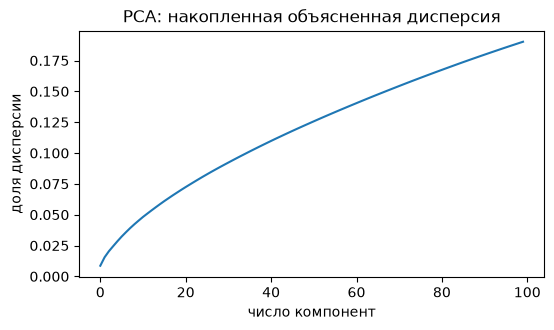

100 компонент объясняют 19.0% дисперсии TF-IDF


In [81]:
t0 = time.time()
texts_topic = topic_texts(all_dialogs)
embedder = TopicEmbedder(N_PCA, max_features=3000, random_state=TSEED).fit(texts_topic)
S = embedder.sparse(texts_topic)
E = embedder.dense(S)
feature_names = embedder.tfidf.get_feature_names_out()
print(f"{time.time() - t0:.0f} сек; TF-IDF: {S.shape}, эмбеддинги: {E.shape}")

evr = embedder.pca.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(np.cumsum(evr)); ax.set_xlabel("число компонент"); ax.set_ylabel("доля дисперсии")
ax.set_title("PCA: накопленная объясненная дисперсия"); plt.show()
print(f"{N_PCA} компонент объясняют {evr.sum():.1%} дисперсии TF-IDF")

### Сколько тем? Инерция, силуэт, Davies-Bouldin, Calinski-Harabasz, BIC (GMM) и устойчивость
Устойчивость: две модели k-средних на разных случайных 80%-подвыборках предсказывают метки всех диалогов,
сравниваем их через ARI. Чем ближе к 1, тем стабильнее разбиение. Правильного k заранее нет,
поэтому смотрим на все показатели вместе и на осмысленность тем.

,inertia,silhouette,davies_bouldin,calinski_harabasz,bic_gmm,stability_ari,min_share
k,,,,,,,
6,1669.109,0.029,3.575,219.520,-3648765.648,0.591,0.005
8,1626.828,0.035,3.535,197.941,-3665430.853,0.614,0.008
10,1595.774,0.029,3.551,178.520,-3671791.005,0.580,0.010
12,1566.330,0.033,3.586,165.846,-3679700.498,0.791,0.010
14,1540.767,0.037,3.342,155.376,-3688983.724,0.533,0.005
16,1508.062,0.043,3.064,151.987,-3693640.508,0.458,0.005
18,1489.082,0.042,3.137,143.272,-3706430.849,0.667,0.003
20,1467.939,0.040,3.154,137.577,-3703416.389,0.660,0.003
22,1447.264,0.042,3.017,133.015,-3717432.273,0.506,0.003


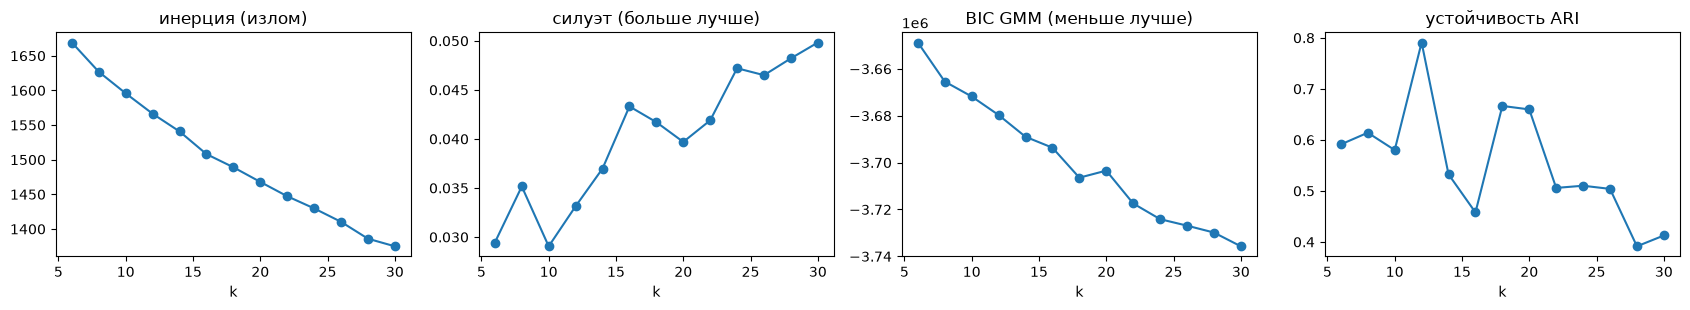

подсказка по силуэту + устойчивости: k = 18 (силуэт на текстах обычно растет вместе с k, поэтому смотрите и на излом инерции, и на осмысленность тем)


In [82]:
rng = np.random.default_rng(TSEED)

def stability_ari(k, n_rep=2, frac=0.8):
    preds = []
    for r in range(n_rep):
        sub = rng.choice(len(E), int(frac * len(E)), replace=False)
        preds.append(KMeans(k, n_init=5, random_state=100 + r).fit(E[sub]).predict(E))
    return adjusted_rand_score(preds[0], preds[1])

rows = []
for k in K_GRID:
    km = KMeans(k, n_init=10, random_state=TSEED).fit(E)
    gm = GaussianMixture(k, covariance_type="diag", random_state=TSEED, max_iter=100).fit(E)
    rows.append({
        "k": k, "inertia": km.inertia_,
        "silhouette": silhouette_score(E, km.labels_, sample_size=min(3000, len(E) - 1), random_state=TSEED),
        "davies_bouldin": davies_bouldin_score(E, km.labels_),
        "calinski_harabasz": calinski_harabasz_score(E, km.labels_),
        "bic_gmm": gm.bic(E), "stability_ari": stability_ari(k),
        "min_share": np.bincount(km.labels_).min() / len(E),
    })
k_table = pd.DataFrame(rows).set_index("k")
display(k_table.round(3))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
for ax, col, title in zip(axes, ["inertia", "silhouette", "bic_gmm", "stability_ari"],
                          ["инерция (излом)", "силуэт (больше лучше)", "BIC GMM (меньше лучше)", "устойчивость ARI"]):
    ax.plot(k_table.index, k_table[col], marker="o"); ax.set_title(title); ax.set_xlabel("k")
plt.tight_layout(); plt.show()

z = lambda s: (s - s.mean()) / (s.std() + 1e-9)
k_table["score"] = z(k_table["silhouette"]) + z(k_table["stability_ari"])
K_SUGGEST = int(k_table["score"].idxmax())
print("подсказка по силуэту + устойчивости: k =", K_SUGGEST,
      "(силуэт на текстах обычно растет вместе с k, поэтому смотрите и на излом инерции, и на осмысленность тем)")

In [83]:

K_TOPICS = K_SUGGEST

print("K_TOPICS =", K_TOPICS)

K_TOPICS = 18


### DBSCAN / HDBSCAN: почему не годятся
На текстовых эмбеддингах плотностные методы оставляют много шума и дают слишком мало или слишком много кластеров.
Нам нужно отнести к теме каждый диалог, а HDBSCAN отдает часть точек в шум.

In [84]:
try:
    import warnings
    warnings.filterwarnings("ignore", category=FutureWarning)
    from sklearn.cluster import HDBSCAN
    sub = np.random.default_rng(0).choice(len(E), min(4000, len(E)), replace=False)
    for mcs in (20, 50):
        lab = HDBSCAN(min_cluster_size=mcs).fit_predict(E[sub])
        print(f"HDBSCAN min_cluster_size={mcs}: кластеров {len(set(lab) - {-1})}, доля шума {np.mean(lab == -1):.0%}")
except Exception as exc:
    print("HDBSCAN недоступен:", exc)

HDBSCAN min_cluster_size=20: кластеров 2, доля шума 54%
HDBSCAN min_cluster_size=50: кластеров 0, доля шума 100%


### Сравнение k-средних, Ward и GMM при выбранном k
Ward строится на подвыборке (на 10 000 объектов слишком много памяти), потом логистическая регрессия переносит метки
на все диалоги. Метрики без истинного разбиения: силуэт, Davies-Bouldin, Calinski-Harabasz; плюс устойчивость и
согласие методов друг с другом (ARI).

In [85]:
methods = {}
for kind in ["kmeans", "gmm", "ward_logreg"]:
    est, lab = fit_topic_clusterer(kind, E, K_TOPICS, seed=TSEED)
    methods[kind] = {"est": est, "labels": lab}

def method_stability(kind, n_rep=3, frac=0.8):
    ref = methods[kind]["labels"]
    scores = []
    for r in range(n_rep):
        sub = np.random.default_rng(200 + r).choice(len(E), int(frac * len(E)), replace=False)
        est, _ = fit_topic_clusterer(kind, E[sub], K_TOPICS, seed=200 + r)
        scores.append(adjusted_rand_score(ref, est.predict(E)))
    return float(np.mean(scores))

rows = {}
for kind, m in methods.items():
    lab = m["labels"]
    sh = np.bincount(lab, minlength=K_TOPICS) / len(lab)
    rows[kind] = {
        "silhouette": silhouette_score(E, lab, sample_size=min(3000, len(E) - 1), random_state=TSEED),
        "davies_bouldin": davies_bouldin_score(E, lab),
        "calinski_harabasz": calinski_harabasz_score(E, lab),
        "stability_ari": method_stability(kind),
        "min_share": sh.min(), "max_share": sh.max(),
    }
method_table = pd.DataFrame(rows).T
display(method_table.round(3))
agree = pd.DataFrame({a: {b: adjusted_rand_score(methods[a]["labels"], methods[b]["labels"]) for b in methods} for a in methods})
print("согласие методов (ARI):"); display(agree.round(3))

,silhouette,davies_bouldin,calinski_harabasz,stability_ari,min_share,max_share
kmeans,0.042,3.137,143.272,0.549,0.003,0.246
gmm,-0.046,4.299,115.097,0.394,0.002,0.172
ward_logreg,0.036,2.914,127.657,0.286,0.003,0.403


согласие методов (ARI):


,kmeans,gmm,ward_logreg
kmeans,1.000,0.211,0.241
gmm,0.211,1.000,0.132
ward_logreg,0.241,0.132,1.000


In [86]:

MAIN_METHOD = "kmeans"
labels_ref = methods[MAIN_METHOD]["labels"]
print("основной метод:", MAIN_METHOD, "| размеры тем:", np.bincount(labels_ref).tolist())

основной метод: kmeans | размеры тем: [390, 108, 140, 361, 887, 272, 900, 2464, 249, 299, 556, 26, 1082, 656, 49, 1074, 186, 301]


### Картинка: t-SNE и PCA на подвыборке

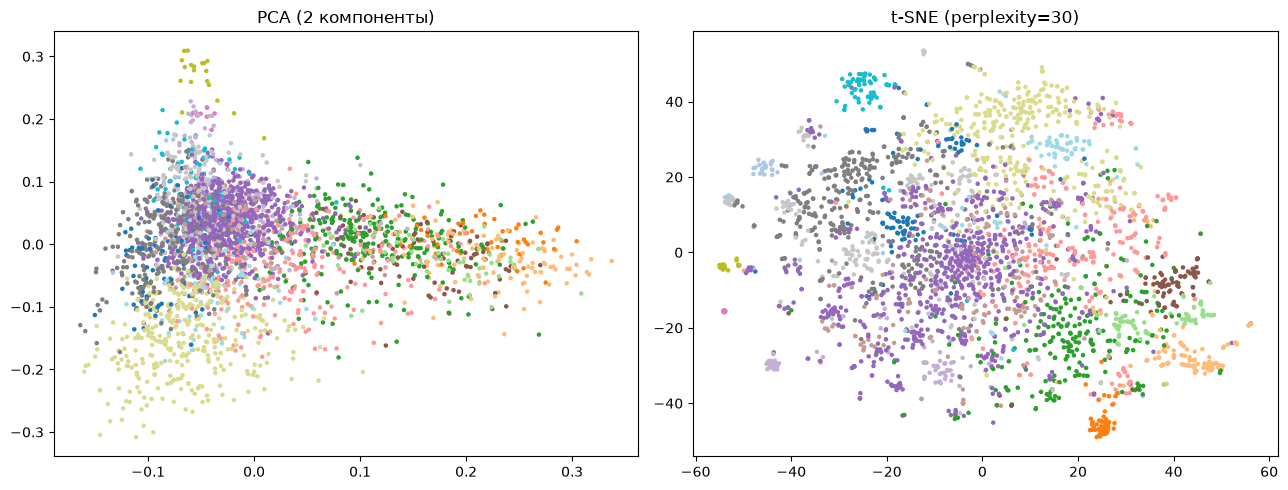

In [87]:
vis = np.random.default_rng(0).choice(len(E), min(3000, len(E)), replace=False)
xy_pca = PCA(2, random_state=0).fit_transform(E[vis])
xy_tsne = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(E[vis])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, xy, title in zip(axes, [xy_pca, xy_tsne], ["PCA (2 компоненты)", "t-SNE (perplexity=30)"]):
    ax.scatter(xy[:, 0], xy[:, 1], c=labels_ref[vis], cmap="tab20", s=5)
    ax.set_title(title)
plt.tight_layout(); plt.show()

### Что в темах: характерные слова и ближайшие к центру диалоги
По этому выводу вручную придумайте название и описание каждой темы.

In [88]:
top_terms = cluster_top_terms(S, labels_ref, feature_names, K_TOPICS, topn=12)
examples = closest_examples(E, labels_ref, K_TOPICS, n=3)
shares = np.bincount(labels_ref, minlength=K_TOPICS) / len(labels_ref)
for c in np.argsort(-shares):
    print(f"\n=== тема {c}: {shares[c]:.1%} диалогов ({int(round(shares[c] * len(labels_ref)))})")
    print("слова:", ", ".join(top_terms[c]))
    for i in examples[c]:
        first = next(t["text"] for t in all_dialogs[i]["turns"] if t["role"] == "user")
        print("   -", repr(first[:130]))


=== тема 7: 24.6% диалогов (2464)
слова: tell, best, gpt, ai, mean, spongebob, ok, chatgpt, game, joke, hypothet, what
   - 'создай название канала про квесты на разные темы.Сделай это на английском'
   - 'How do you pronounce "Ringarë"?'
   - '⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣿⣿⣿⣿⠟⠉⠀⠀⠀⠀⠀⠀⠀⠀⠀⣰⠁⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀\n⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢠⣿⣿⣿⠟⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⡇⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀\n⠀⠀⠀⠀⠀⠀⠀⠀'

=== тема 12: 10.8% диалогов (1082)
слова: stori, like, go, feel, friend, would, thing, come, look, even, say, someth
   - "ترجمه کن به فارسی\n“Muscles don't respond until the ninth or tenth repetition of the\nexercise; then you start to feel the pain... a"
   - 'How can I decenter men and stop seeking their validation when they don’t commit to me romantically?'
   - '写出下列单词的中文词义，并用peppa pig的词汇水平，举出1个英文例句（非对话，不要中文翻译），并按顺序编号，单词如下Expect, especially, in front of, Puppet, loudly, snoring, theatre, po'

=== тема 15: 10.7% диалогов (1074)
слова: develop, manag, provid, research, busi, effect, improv, experi, product, t

### Названия и описания тем
Заполните словари **вручную** по выводу выше (ключ = номер темы). Пока не заполнено, имя строится
автоматически из характерных слов. После изменения запустите ячейку и все ячейки ниже.

In [89]:
TOPIC_NAMES = {
    0:  "Книги и краткие содержания",
    1:  "Видеоигры и игровые персонажи",
    2:  "Помощь с курсовыми и научными работами",
    3:  "ИИ, ChatGPT и промпты",
    4:  "Солянка: общие вопросы и поп-культура",
    5:  "Деловая переписка и письма",
    6:  "Ошибки в коде (Traceback)",
    7:  "Научные исследования и медицина",
    8:  "Веб-разработка (HTML/JS/React)",
    9:  "Excel и макросы VBA",
    10: "История, политика и география",
    11: "Финансы и инвестиции",
    12: "Грамматика и исправление текста",
    13: "Java, C++ и ООП",
    14: "Фанфики по играм и аниме",
    15: "Креативное письмо и рассказы",
    16: "Короткие тексты: стихи, твиты, посты",
    17: "Сценарии боев и MMA",
    18: "Переводы на другие языки",
    19: "Бизнес, менеджмент и маркетинг",
    20: "SQL, таблицы и работа с данными",
    21: "Математика и уравнения",
    22: "Шутки и светская болтовня",
    23: "Программирование на Python",
    24: "Симуляции сезонов NBA",
    25: "Linux, консоль и установка софта",
    26: "Алготрейдинг и торговые боты",
    27: "Значения слов и лингвистика",
    28: "Генерация списков и идей",
    29: "Химия и физика"
}

TOPIC_DESCR = {
    0:  "Обсуждение книг, поиск литературы, просьбы сделать краткое содержание по главам.",
    1:  "Вопросы про видеоигры, персонажей, сюжеты и игровые механики.",
    2:  "Просьбы написать эссе, курсовую, диплом или сделать обзор литературы.",
    3:  "Вопросы про нейросети, ChatGPT, работу с промптами и генерацию картинок.",
    4:  "Самый большой кластер: случайные вопросы, факты о знаменитостях, гипотетические ситуации.",
    5:  "Составление официальных писем, email, ответы клиентам и деловая переписка.",
    6:  "Обсуждение ошибок в коде, разбор Traceback и поиск багов.",
    7:  "Вопросы про здоровье, психологию, научные исследования и влияние разных факторов.",
    8:  "Верстка сайтов, работа с HTML, CSS, JavaScript и React.",
    9:  "Работа с ячейками Excel, написание формул и макросов на VBA.",
    10: "Вопросы по истории, войнам, политическим режимам и географическим фактам.",
    11: "Расчет цен, прибыли, анализ рынка и вопросы про инвестиции.",
    12: "Исправление орфографии, пунктуации и стилистики предложений.",
    13: "Вопросы по классам, методам и синтаксису строго типизированных языков (Java, C++).",
    14: "Сценарии и истории по мотивам игр Sonic, Freedom Planet, Naruto (AU).",
    15: "Придумывание историй, сценариев, обсуждение чувств и отношений персонажей.",
    16: "Генерация коротких постов, твитов, стихов и юмористических текстов.",
    17: "Симуляции боев, рестлинг, смешанные единоборства (MMA).",
    18: "Перевод текстов и слов на английский, китайский, испанский и другие языки.",
    19: "Вопросы про бизнес-планы, менеджмент, маркетинг и управление командами.",
    20: "Запросы к базам данных, SQL-код, работа с таблицами и Pandas.",
    21: "Решение математических задач, уравнений, работа с функциями и числами.",
    22: "Просьбы рассказать шутку, анекдот или просто поболтать на отвлеченные темы.",
    23: "Написание кода на Python, работа с библиотеками (numpy, pandas) и функциями.",
    24: "Создание вымышленных сезонов NBA, драфты и фэнтези-баскетбол.",
    25: "Установка программ, работа в командной строке Linux, настройка серверов.",
    26: "Код для торговых ботов, индикаторы (EMA), Binance API и рыночные сигналы.",
    27: "Вопросы про значение конкретных слов, лингвистику и словарные определения.",
    28: "Просьбы сгенерировать список: топ-10, идеи, рецепты, ингредиенты.",
    29: "Вопросы по химии, физике, элементам, атомам и химическим реакциям."
}
names = [TOPIC_NAMES.get(c, f"t{c}: " + ", ".join(top_terms[c][:3])) for c in range(K_TOPICS)]
assert len(set(names)) == K_TOPICS, "названия тем должны быть уникальными"

topic_table = pd.DataFrame({
    "тема": names,
    "описание": [TOPIC_DESCR.get(c, "") for c in range(K_TOPICS)],
    "доля": shares.round(3),
    "диалогов": np.bincount(labels_ref, minlength=K_TOPICS),
    "слова": [", ".join(top_terms[c][:8]) for c in range(K_TOPICS)],
    "примеры": [" | ".join(next(t["text"] for t in all_dialogs[i]["turns"] if t["role"] == "user")[:70].replace("\n", " ")
                           for i in examples[c][:3]) for c in range(K_TOPICS)],
}).sort_values("доля", ascending=False)
display(topic_table)

,тема,описание,доля,диалогов,слова,примеры
7,Научные исследования и медицина,"Вопросы про здоровье, психологию, научные иссл...",0.246,2464,"tell, best, gpt, ai, mean, spongebob, ok, chatgpt",создай название канала про квесты на разные те...
12,Грамматика и исправление текста,"Исправление орфографии, пунктуации и стилистик...",0.108,1082,"stori, like, go, feel, friend, would, thing, come",ترجمه کن به فارسی “Muscles don't respond until...
15,Креативное письмо и рассказы,"Придумывание историй, сценариев, обсуждение чу...",0.107,1074,"develop, manag, provid, research, busi, effect...",are there feds in DC | create a meta descripti...
6,Ошибки в коде (Traceback),"Обсуждение ошибок в коде, разбор Traceback и п...",0.090,900,"number, valu, calcul, function, given, answer,...",38.\tDefinition of conditional probability | A...
4,Солянка: общие вопросы и поп-культура,"Самый большой кластер: случайные вопросы, факт...",0.089,887,"code, file, python, use, error, script, comman...",on arduino board you have a pcm liberary that ...
13,"Java, C++ и ООП","Вопросы по классам, методам и синтаксису строг...",0.066,656,"write, word, short, stori, write short, pleas ...","Write a composition entitled ""Should Her oic D..."
10,"История, политика и география","Вопросы по истории, войнам, политическим режим...",0.056,556,"give, exampl, give exampl, pleas give, explain...",Give me some Italian usernames for reddit as a...
0,Книги и краткие содержания,"Обсуждение книг, поиск литературы, просьбы сде...",0.039,390,"war, govern, empir, china, countri, world, sta...",What is benign neglect and how did it affect t...
3,"ИИ, ChatGPT и промпты","Вопросы про нейросети, ChatGPT, работу с промп...",0.036,361,"def, py, self, file, import, print, return, py...","ERROR: Need an action (debug, edit, get, list,..."
17,Сценарии боев и MMA,"Симуляции боев, рестлинг, смешанные единоборст...",0.030,301,"email, pleas, thank, regard, us, custom, reque...","edit: I hope you are doing well. First of all,..."


### Классификаторы тем: 3 базовых + своя
Классификатор получает метки основной кластеризации и должен относить новый диалог к одной из тем.
Базовые: LogReg на PCA-эмбеддингах, MultinomialNB и LinearSVC на TF-IDF. Своя: `custom_svc_rbf` --
SVC с ядром RBF (ядровой переход, занятие 5) на PCA-эмбеддингах: нелинейная граница между темами.
Оценка: 5 частей по группам (одинаковая первая реплика не делится между train и val), метки = темы кластеризации.
Для сравнения добавлены ARI с эталонной кластеризацией на отложенных частях и константа (`dummy`).

In [90]:
groups_topic = group_ids(all_dialogs)
oof = {name: np.zeros(len(E), dtype=int) for name in TOPIC_CLASSIFIERS + ["dummy_most_frequent"]}
for tr, va in group_kfold_splits(groups_topic, 5, seed=TSEED):
    for name in TOPIC_CLASSIFIERS:
        est, space = fit_topic_classifier(name, E[tr], S[tr], labels_ref[tr])
        oof[name][va] = est.predict(S[va] if space == "sparse" else E[va])
    oof["dummy_most_frequent"][va] = DummyClassifier(strategy="most_frequent").fit(E[tr], labels_ref[tr]).predict(E[va])

clf_table = pd.DataFrame({
    name: {"accuracy": accuracy_score(labels_ref, pred), "macro_F1": f1_score(labels_ref, pred, average="macro"),
           "ARI_vs_ref": adjusted_rand_score(labels_ref, pred)}
    for name, pred in oof.items()}).T
display(clf_table.round(3))

,accuracy,macro_F1,ARI_vs_ref
base_logreg,0.935,0.937,0.856
base_nb,0.698,0.715,0.409
base_svm,0.866,0.881,0.711
custom_svc_rbf,0.922,0.931,0.831
dummy_most_frequent,0.246,0.022,0.000


### Обучение на всех диалогах и сохранение в artifacts/
Названия тем зашиваются в модели вместе с эмбеддером (TF-IDF + PCA).

In [91]:
final_topic_models = {}
for name in TOPIC_CLASSIFIERS:
    est, space = fit_topic_classifier(name, E, S, labels_ref)
    final_topic_models[name] = TopicModel(embedder, est, names, space=space)
save_topic_models(final_topic_models)

loaded_topics = init_topic_models(TRAIN_PATH)
sample = all_dialogs[:200]
for name, m in final_topic_models.items():
    assert predict_topic(m, sample) == predict_topic(loaded_topics[name], sample), name
print("модели тем сохранены и проверены:", list(loaded_topics))
pred_all = {n: pd.Series(predict_topic(m, all_dialogs)).value_counts(normalize=True).round(3) for n, m in loaded_topics.items()}
display(pd.DataFrame(pred_all).fillna(0))

модели тем сохранены и проверены: ['base_logreg', 'base_nb', 'base_svm', 'custom_svc_rbf']


,base_logreg,base_nb,base_svm,custom_svc_rbf
Excel и макросы VBA,0.030,0.031,0.030,0.030
"Java, C++ и ООП",0.066,0.046,0.066,0.066
Веб-разработка (HTML/JS/React),0.024,0.012,0.025,0.025
Видеоигры и игровые персонажи,0.010,0.009,0.011,0.011
Грамматика и исправление текста,0.108,0.117,0.108,0.108
Деловая переписка и письма,0.026,0.026,0.027,0.027
"ИИ, ChatGPT и промпты",0.036,0.038,0.036,0.036
"История, политика и география",0.054,0.026,0.055,0.056
Книги и краткие содержания,0.037,0.037,0.039,0.039
"Короткие тексты: стихи, твиты, посты",0.018,0.016,0.018,0.019


### Метрики лучшей модели реакции по темам (аналог з 12 лаб)
Предсказания реакции -- честные out-of-fold на всех 3000 размеченных диалогах (кросс-валидация по группам),
темы -- от классификатора `base_logreg`. Пороги своей модели подбирались на dev, так что оценка слегка оптимистична.

In [92]:
all_idx = np.arange(len(L))
if best_name == "custom_turn_h8":
    P_all, rows_all = oof_turn_proba(all_idx, 0)
    oof_react = turn_dialog_pred(P_all, rows_all, all_idx, BEST_TN, BEST_TP)
else:
    oof_react = oof_dialog_model(best_name, all_idx, 0)
topic_of_L = np.array(predict_topic(final_topic_models["base_logreg"], L))

rows = []
for t in sorted(set(topic_of_L)):
    m = topic_of_L == t
    y_t, p_t = y_all[m], oof_react[m]
    rec = recall_score(y_t, p_t, labels=CLASSES, average=None, zero_division=0)
    sup = np.array([(y_t == c).sum() for c in CLASSES])
    rows.append({
        "тема": t, "n": int(m.sum()), "доля positive": round((y_t == "positive").mean(), 3),
        "доля negative": round((y_t == "negative").mean(), 3),
        "macro_F1": round(f1_score(y_t, p_t, labels=CLASSES, average="macro", zero_division=0), 3),
        **{f"recall_{c[:3]}": (round(r, 3) if s > 0 else np.nan) for c, r, s in zip(CLASSES, rec, sup)},
    })
by_topic = pd.DataFrame(rows).sort_values("n", ascending=False)
display(by_topic)
print("разница macro_F1 между лучшей и худшей темой:", round(by_topic["macro_F1"].max() - by_topic["macro_F1"].min(), 3),
      "(темы с n < 30 шумные)")

,тема,n,доля positive,доля negative,macro_F1,recall_neg,recall_neu,recall_pos
11,Научные исследования и медицина,730,0.125,0.264,0.619,0.503,0.789,0.582
10,Креативное письмо и рассказы,346,0.092,0.202,0.522,0.214,0.848,0.500
4,Грамматика и исправление текста,341,0.167,0.188,0.513,0.266,0.695,0.684
14,Солянка: общие вопросы и поп-культура,274,0.080,0.504,0.554,0.884,0.342,0.409
12,Ошибки в коде (Traceback),268,0.052,0.422,0.662,0.699,0.716,0.643
1,"Java, C++ и ООП",196,0.061,0.173,0.635,0.324,0.853,0.917
7,"История, политика и география",157,0.134,0.248,0.577,0.385,0.722,0.714
8,Книги и краткие содержания,111,0.072,0.162,0.530,0.222,0.906,0.500
6,"ИИ, ChatGPT и промпты",105,0.048,0.695,0.483,0.973,0.222,0.200
0,Excel и макросы VBA,101,0.079,0.515,0.587,0.885,0.390,0.500


разница macro_F1 между лучшей и худшей темой: 0.329 (темы с n < 30 шумные)


### Выводы по задаче 2
- Число тем K: выбрано по таблице (инерция, силуэт, BIC, устойчивость) и по осмысленности названий.
- Силуэт на текстах низкий разбиения мягкие: тем не менее разбиения устойчивы (ARI на подвыборках) и согласуются между методами.
- DBSCAN/HDBSCAN оставляют много шума, нам нужны все диалоги значит не берем.
- Классификаторы воспроизводят темы кластеризации; LogReg на эмбеддингах совпадает с k-средних почти по построению (метки получены из тех же эмбеддингов), честнее смотреть на модели на TF-IDF.